# 6. 제조업 실시간 이상탐지 시스템 구축 실습

박서준 (인공지능학과)

VisA `pcb4` 데이터(정상 1,005장, 불량 100장)로 PaDiM, AutoEncoder, One-Class SVM을 돌려서 비교하고, PaDiM으로 Gradio 데모까지 띄워봤다. Colab T4에서 돌렸고 강의 코드는 설치 셀에서 wget 주석만 풀고 그대로 썼다.

### 이상탐지를 위한 라이브러리 설치

In [1]:
# !pip install anomalib
# !pip install pytorch-lightning

In [2]:
# Colab에 wget이 없어서 주석 풀고 설치 (gradio는 이미 깔려 있었음)
!pip install wget gradio

  Preparing metadata (setup.py) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9686 sha256=1049328c211ddb56b9b77001e0fe95fa90acbfb1d853d5967461faf37fbae770
  Stored in directory: /root/.cache/pip/wheels/8a/b8/04/0c88fb22489b0c049bee4e977c5689c7fe597d6c4b0e7d0b6a
Successfully built wget


## VisA 데이터셋 다운로드

In [3]:
import os
import wget
import zipfile
from pathlib import Path
import pandas as pd
import tarfile

def download_visa_dataset():
    """VisA 데이터셋 다운로드"""
    base_url = "https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"
    filename = "VisA_20220922.tar"
    extract_dir = "./VisA"


    if not os.path.exists(filename):
        print("VisA 데이터셋 다운로드 중...")
        wget.download(base_url, filename)
        print("\n다운로드 완료!")

    ## 압축 해제
    if not os.path.exists(extract_dir):
        os.makedirs(extract_dir, exist_ok=True)
        with tarfile.open(filename, 'r') as tar:
            tar.extractall(path=extract_dir)
        print("압축 해제 완료!")

def check_visa_structure(data_path="./VisA_pytorch/VisA"):
    """VisA 데이터셋 구조 확인"""
    data_path = Path(data_path)
    print(f"VisA 데이터셋 경로: {data_path}")

    categories = []
    for category_dir in data_path.iterdir():
        if category_dir.is_dir():
            categories.append(category_dir.name)
            print(f"\n카테고리: {category_dir.name}")

            # 이미지 개수 확인
            images_dir = category_dir / "Data" / "Images"
            if images_dir.exists():
                normal_count = len(list((images_dir / "Normal").glob("*"))) if (images_dir / "Normal").exists() else 0


                print(f"  정상 이미지: {normal_count}개")

    return categories

In [4]:
download_visa_dataset()

VisA 데이터셋 다운로드 중...

다운로드 완료!


/tmp/ipykernel_613/1396103325.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_dir)


압축 해제 완료!


In [5]:
check_visa_structure(data_path="./VisA")

VisA 데이터셋 경로: VisA

카테고리: macaroni1
  정상 이미지: 1000개

카테고리: fryum
  정상 이미지: 500개

카테고리: capsules
  정상 이미지: 602개

카테고리: macaroni2
  정상 이미지: 1000개

카테고리: pipe_fryum
  정상 이미지: 500개

카테고리: pcb4
  정상 이미지: 1005개

카테고리: candle
  정상 이미지: 1000개

카테고리: chewinggum
  정상 이미지: 503개

카테고리: split_csv

카테고리: pcb3
  정상 이미지: 1006개

카테고리: cashew
  정상 이미지: 500개

카테고리: pcb2
  정상 이미지: 1001개

카테고리: pcb1
  정상 이미지: 1004개


['macaroni1',
 'fryum',
 'capsules',
 'macaroni2',
 'pipe_fryum',
 'pcb4',
 'candle',
 'chewinggum',
 'split_csv',
 'pcb3',
 'cashew',
 'pcb2',
 'pcb1']

VisA에는 PCB, 캡슐, 양초, 마카로니 같은 제품 12개가 있다. `split_csv`는 제품 폴더가 아니라서 개수가 안 찍혔다. 이번엔 `pcb4`만 썼다.

### Dataloader 구현

In [6]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms
import cv2
import numpy as np

class VisADataset(Dataset):
    def __init__(self, data_path, category, transform=None, is_train=True, include_mask=False, train_ratio=0.8):
        self.data_path = Path(data_path)
        self.category = category
        self.transform = transform
        self.is_train = is_train
        self.include_mask = include_mask

        self.image_paths = []
        self.mask_paths = []
        self.labels = []
        self.defect_types = []

        category_path = self.data_path / category

        # CSV 파일에서 메타데이터 로드
        csv_path = category_path / "image_anno.csv"
        if csv_path.exists():
            df = pd.read_csv(csv_path)
            print(f"CSV 컬럼: {df.columns.tolist()}")

            # 정상/비정상 데이터 분리
            normal_df = df[df['label'] == 'normal'].copy()
            anomaly_df = df[df['label'] != 'normal'].copy()

            if self.is_train:
                # 훈련용: 정상 데이터의 일부만 사용
                train_size = int(len(normal_df) * train_ratio)
                selected_df = normal_df.iloc[:train_size]
                print(f"훈련용 정상 데이터: {len(selected_df)}개")
            else:
                # 테스트용: 나머지 정상 데이터 + 모든 비정상 데이터
                test_normal_size = len(normal_df) - int(len(normal_df) * train_ratio)
                test_normal_df = normal_df.iloc[-test_normal_size:] if test_normal_size > 0 else pd.DataFrame()
                selected_df = pd.concat([test_normal_df, anomaly_df], ignore_index=True)
                print(f"테스트용 정상 데이터: {len(test_normal_df)}개")
                print(f"테스트용 비정상 데이터: {len(anomaly_df)}개")

            # 데이터 로드
            for _, row in selected_df.iterrows():
                # 이미지 경로 처리 (중복 경로 제거)
                image_rel_path = row['image']
                if image_rel_path.startswith(category + '/'):
                    image_path = self.data_path / image_rel_path
                else:
                    image_path = category_path / image_rel_path

                if image_path.exists():
                    self.image_paths.append(str(image_path))
                    self.labels.append(0 if row['label'] == 'normal' else 1)
                    self.defect_types.append(row['label'])

                    # 마스크 경로 처리
                    if pd.notna(row['mask']) and self.include_mask:
                        mask_rel_path = row['mask']
                        if mask_rel_path.startswith(category + '/'):
                            mask_path = self.data_path / mask_rel_path
                        else:
                            mask_path = category_path / mask_rel_path
                        self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                    else:
                        self.mask_paths.append(None)
                else:
                    print(f"이미지 파일을 찾을 수 없습니다: {image_path}")
        else:
            print("CSV 파일이 없습니다. 폴더 구조를 기반으로 데이터를 로드합니다.")
            self._load_from_folder_structure()

    def _load_from_folder_structure(self):
        """폴더 구조를 기반으로 데이터 로드 (CSV가 없는 경우)"""
        category_path = self.data_path / self.category
        images_path = category_path / "Data" / "Images"
        masks_path = category_path / "Data" / "Masks"

        if self.is_train:
            # 훈련용: 정상 이미지만 사용
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)  # 정상: 0
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)
        else:
            # 테스트용: 정상 + 비정상 이미지
            # 정상 이미지
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)

            # 비정상 이미지
            anomaly_path = images_path / "Anomaly"
            if anomaly_path.exists():
                for img_path in anomaly_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(1)  # 이상: 1
                        self.defect_types.append('anomaly')

                        # 마스크 경로 찾기
                        if self.include_mask:
                            mask_name = img_path.stem + '.png'  # 확장자를 png로 변경
                            mask_path = masks_path / "Anomaly" / mask_name
                            self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                        else:
                            self.mask_paths.append(None)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 이미지 로드
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]

        # 마스크 로드 (있는 경우)
        mask = None
        if self.include_mask and self.mask_paths[idx] is not None:
            try:
                mask = Image.open(self.mask_paths[idx]).convert('L')
            except:
                mask = None

        # 변환 적용
        if self.transform:
            image = self.transform(image)
            if mask is not None:
                mask_transform = transforms.Compose([
                    transforms.Resize((256, 256)),
                    transforms.ToTensor()
                ])
                mask = mask_transform(mask)

        result = {
            'image': image,
            'label': label,
            'defect_type': self.defect_types[idx]
        }

        if mask is not None:
            result['mask'] = mask

        return result

In [7]:
# 데이터 전처리 정의
def get_visa_transforms():
    train_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    test_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    return train_transform, test_transform


In [8]:
def create_visa_data_loaders(data_path, category, batch_size=32, include_mask=False, train_ratio=0.8):
    """
    VisA 데이터셋용 데이터 로더 생성

    Args:
        data_path: VisA 데이터셋 경로
        category: 카테고리 이름
        batch_size: 배치 크기
        include_mask: 마스크 포함 여부
        train_ratio: 훈련 데이터 비율 (정상 데이터에서)
    """
    train_transform, test_transform = get_visa_transforms()

    train_dataset = VisADataset(
        data_path, category,
        transform=train_transform,
        is_train=True,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    test_dataset = VisADataset(
        data_path, category,
        transform=test_transform,
        is_train=False,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,  # Windows에서 문제가 있을 수 있으므로 낮춤
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    return train_loader, test_loader


## 시각화

In [9]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

def visualize_visa_samples(dataset, num_samples=8):
    """VisA 데이터셋 샘플 시각화"""
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)

    for i, idx in enumerate(indices):
        sample = dataset[idx]
        image = sample['image']
        label = sample['label']
        defect_type = sample['defect_type']

        # 텐서를 이미지로 변환
        if isinstance(image, torch.Tensor):
            image = image.permute(1, 2, 0)
            image = image * torch.tensor([0.229, 0.224, 0.225]) + torch.tensor([0.485, 0.456, 0.406])
            image = torch.clamp(image, 0, 1)

        axes[i].imshow(image)
        title = f"{'Normal' if label == 0 else 'Anomaly'}"
        if defect_type != 'normal':
            title += f"\n({defect_type})"
        axes[i].set_title(title)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

def visualize_with_mask(dataset, idx):
    """이미지와 마스크 함께 시각화"""
    sample = dataset[idx]
    image = sample['image']
    mask = sample.get('mask')
    label = sample['label']
    defect_type = sample['defect_type']

    # 이미지 정규화 해제
    if isinstance(image, torch.Tensor):
        image = image.permute(1, 2, 0)
        image = image * torch.tensor([0.229, 0.224, 0.225]) + torch.tensor([0.485, 0.456, 0.406])
        image = torch.clamp(image, 0, 1)

    if mask is not None:
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # 원본 이미지
        axes[0].imshow(image)
        axes[0].set_title('Original Image')
        axes[0].axis('off')

        # 마스크
        axes[1].imshow(mask.squeeze(), cmap='gray')
        axes[1].set_title('Anomaly Mask')
        axes[1].axis('off')

        # 오버레이
        overlay = image.clone()
        if mask.sum() > 0:
            mask_resized = torch.nn.functional.interpolate(
                mask.unsqueeze(0),
                size=image.shape[:2],
                mode='nearest'
            ).squeeze()
            overlay[mask_resized > 0.01] = torch.tensor([255.0, 0.0, 0.0])  # 빨간색으로 표시

        axes[2].imshow(overlay)
        axes[2].set_title(f'Overlay ({defect_type})')
        axes[2].axis('off')

    else:
        plt.figure(figsize=(8, 6))
        plt.imshow(image)
        plt.title(f"{'Normal' if label == 0 else 'Anomaly'} - {defect_type}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()


In [10]:
def plot_visa_statistics(data_path, category):
    """VisA 데이터셋 통계 시각화"""
    category_path = Path(data_path) / category
    csv_path = category_path / "image_anno.csv"

    if csv_path.exists():
        df = pd.read_csv(csv_path)

        fig, axes = plt.subplots(2, 2, figsize=(15, 10))

        title1 = 'Overall Class Distribution (Normal vs Anomaly)'
        title2 = 'Main Defect Types Distribution'
        title3 = 'Mask Availability Distribution'
        title4 = 'All Labels Distribution (Top 10)'
        xlabel2 = 'Number of Images'
        ylabel3 = 'Number of Images'
        xlabel4 = 'Number of Images'
        mask_labels = ['With Mask', 'Without Mask']

        # 전체 클래스 분포 (정상 vs 비정상)
        binary_labels = ['Normal' if label == 'normal' else 'Anomaly' for label in df['label']]
        class_counts = pd.Series(binary_labels).value_counts()
        axes[0, 0].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%')
        axes[0, 0].set_title(title1)

        # 결함 유형별 상세 분포
        anomaly_df = df[df['label'] != 'normal']
        if not anomaly_df.empty:
            # 결함 유형을 단순화 (콤마로 구분된 경우 첫 번째만 사용)
            simplified_defects = [label.split(',')[0] for label in anomaly_df['label']]
            defect_counts = pd.Series(simplified_defects).value_counts()

            axes[0, 1].barh(defect_counts.index, defect_counts.values)
            axes[0, 1].set_title(title2)
            axes[0, 1].set_xlabel(xlabel2)

        # 마스크 유무 분포
        mask_counts = df['mask'].notna().value_counts()
        mask_labels_mapped = [mask_labels[0] if has_mask else mask_labels[1] for has_mask in mask_counts.index]
        axes[1, 0].bar(mask_labels_mapped, mask_counts.values)
        axes[1, 0].set_title(title3)
        axes[1, 0].set_ylabel(ylabel3)

        # 전체 결함 유형 (복합 결함 포함)
        all_defect_counts = df['label'].value_counts()
        # 상위 10개만 표시
        top_defects = all_defect_counts.head(10)
        axes[1, 1].barh(range(len(top_defects)), top_defects.values)
        axes[1, 1].set_yticks(range(len(top_defects)))
        axes[1, 1].set_yticklabels(top_defects.index)
        axes[1, 1].set_title(title4)
        axes[1, 1].set_xlabel(xlabel4)

        plt.tight_layout()
        plt.show()

        # 데이터 요약 출력

        print(f"Total images: {len(df)}")
        print(f"Normal images: {len(df[df['label'] == 'normal'])}")
        print(f"Anomaly images: {len(df[df['label'] != 'normal'])}")
        print(f"Images with masks: {df['mask'].notna().sum()}")
        print(f"Unique defect types: {df['label'].nunique()}")

    else:
        error_msg = f"CSV 파일을 찾을 수 없습니다: {csv_path}" if KOREAN_FONT_AVAILABLE else f"CSV file not found: {csv_path}"
        print(error_msg)


In [11]:
DATA_PATH = "./VisA" # <--- 실제 데이터셋 경로로 변경하세요!
CATEGORY_NAME = "pcb4" # VisA 데이터셋의 카테고리 중 하나 (예: 'pcb', 'capsules' 등)
BATCH_SIZE = 8 # 메모리에 따라 조절
D_REDUCED = 100 # PaDiM의 축소된 특징 차원
IMG_SIZE = 256  # 입력 이미지 크기 (예시)
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]
# PaDiM 내부에서 특징맵을 리사이즈할 크기 (고정)
PADIM_PATCH_SIZE = 28

train_loader, test_loader = create_visa_data_loaders(DATA_PATH, CATEGORY_NAME, BATCH_SIZE, include_mask=True)

CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개


정상 804장으로만 학습하고 테스트는 남은 정상 201장 + 불량 100장이다. 불량을 학습에 아예 안 쓰는 게 일반 분류랑 제일 다른 점 같다. 공장에서는 불량 사진이 귀하니까 이 방식이 더 현실적일 것 같다.

학습 transform에 `RandomHorizontalFlip`이 들어가 있는데, PCB는 좌우를 뒤집으면 커넥터 위치가 바뀌어서 실제로는 없는 모양이 된다. 이게 도움이 될지 의문이었다. (뒤 추가 분석 D에서 빼고 돌려보니 AUROC가 0.02 정도 올랐다.)

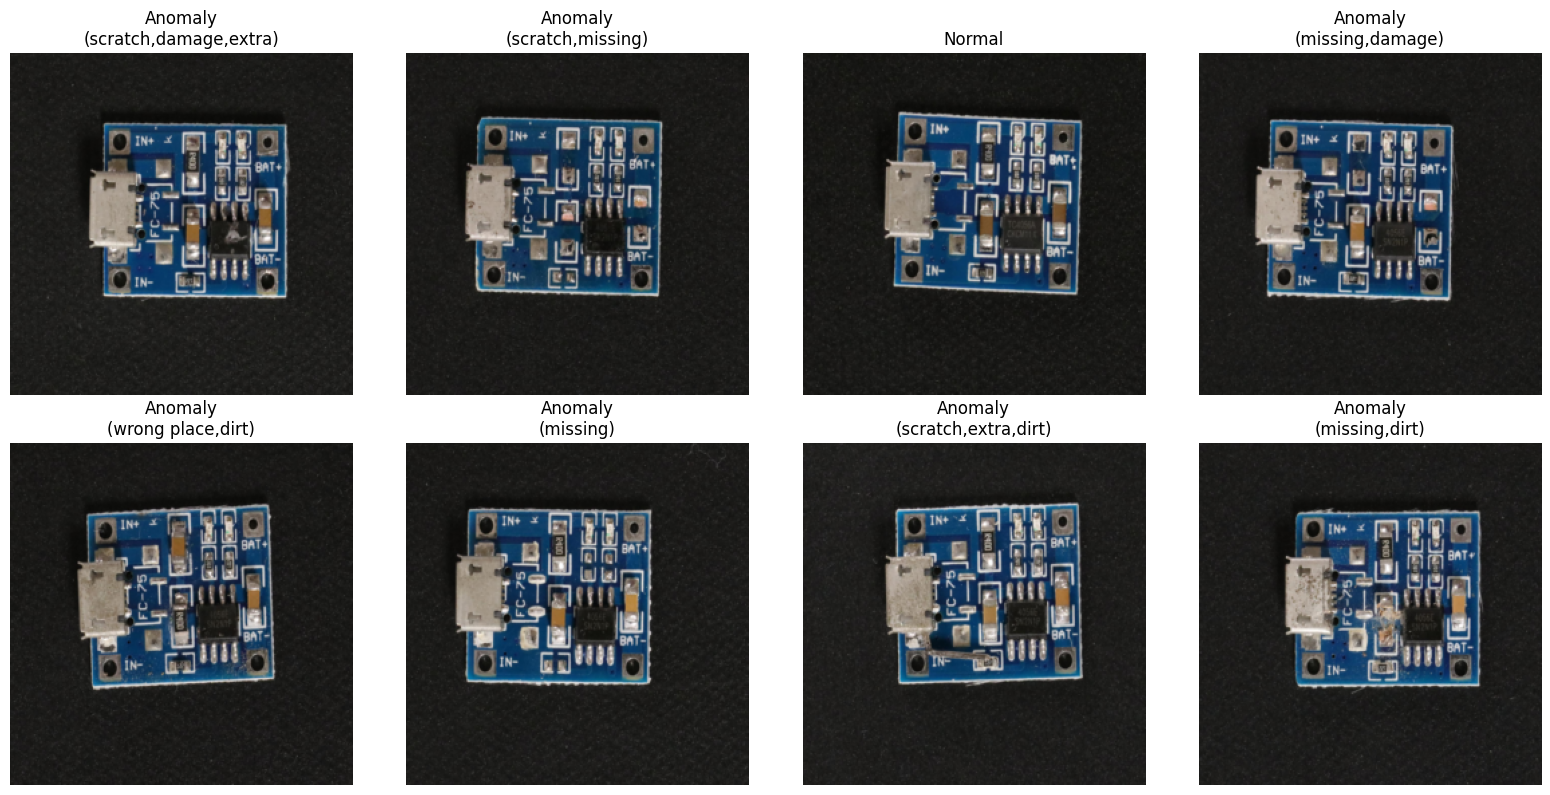

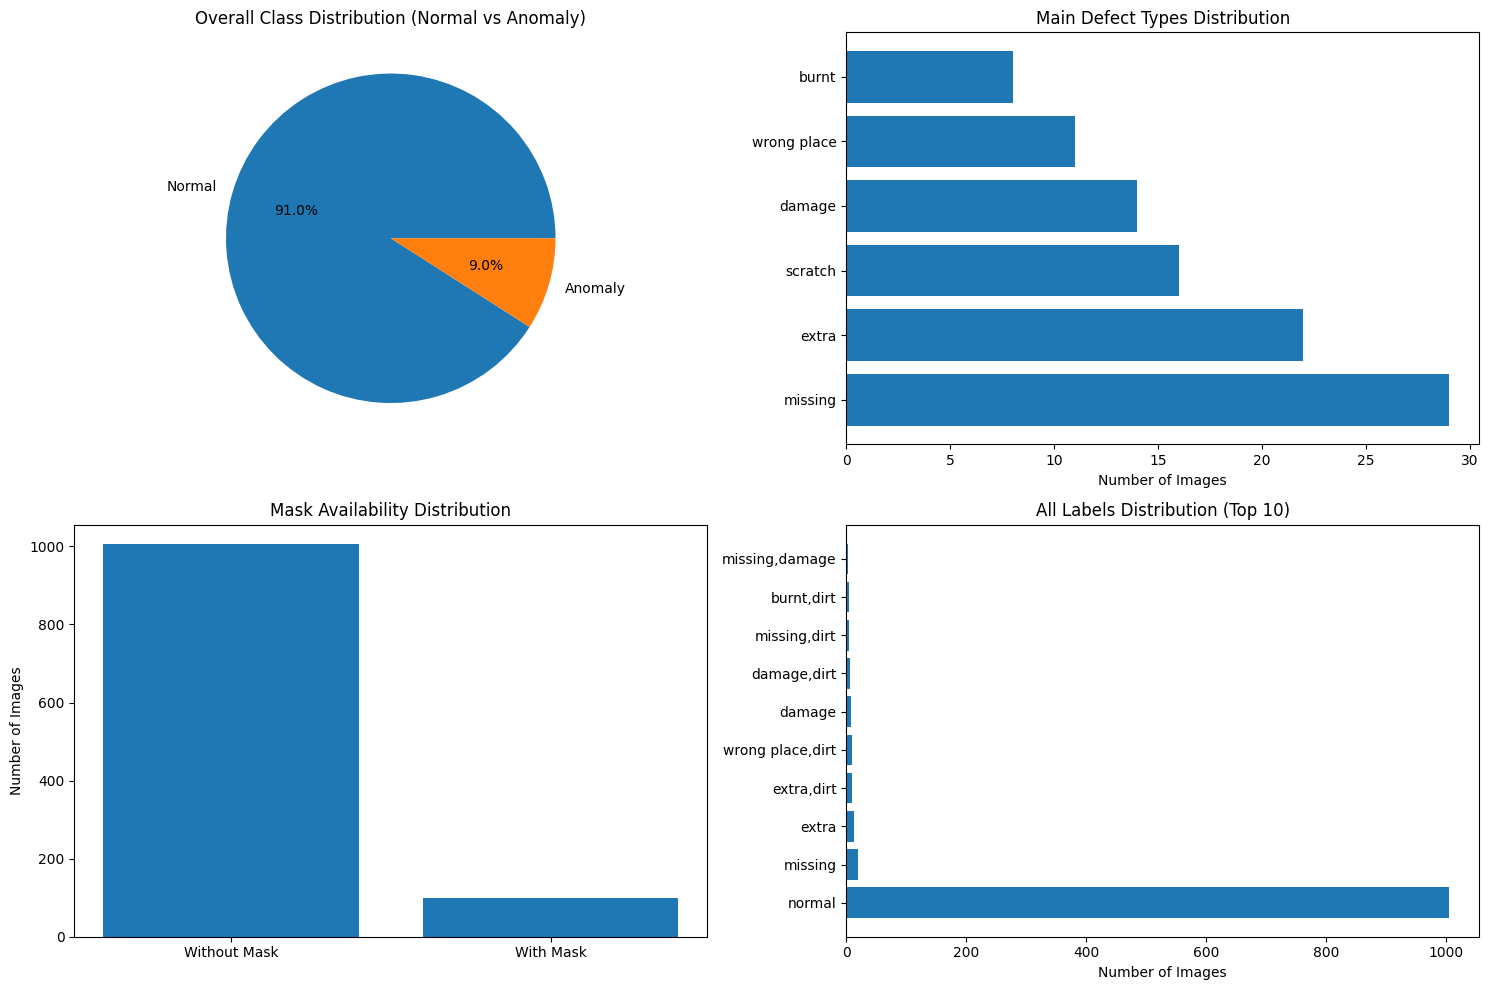

Total images: 1105
Normal images: 1005
Anomaly images: 100
Images with masks: 100
Unique defect types: 27


In [12]:
visualize_visa_samples(test_loader.dataset)
plot_visa_statistics(DATA_PATH, CATEGORY_NAME)

랜덤으로 뽑은 8장 중 7장이 불량이었는데 눈으로는 정상이랑 거의 구분이 안 됐다.

통계 그래프를 보면 전체 1,105장 중 불량은 100장(9%)뿐이다. 첫 번째 라벨 기준으로 missing(부품 누락)이 제일 많고 burnt가 제일 적다. 불량 100장은 전부 마스크가 있다.

`Unique defect types: 27`은 normal까지 포함한 숫자고, `scratch,missing`처럼 겹친 라벨을 따로 세서 많아졌다. 오른쪽 아래 그래프는 normal 막대가 너무 길어서 불량 라벨끼리는 비교가 잘 안 된다.

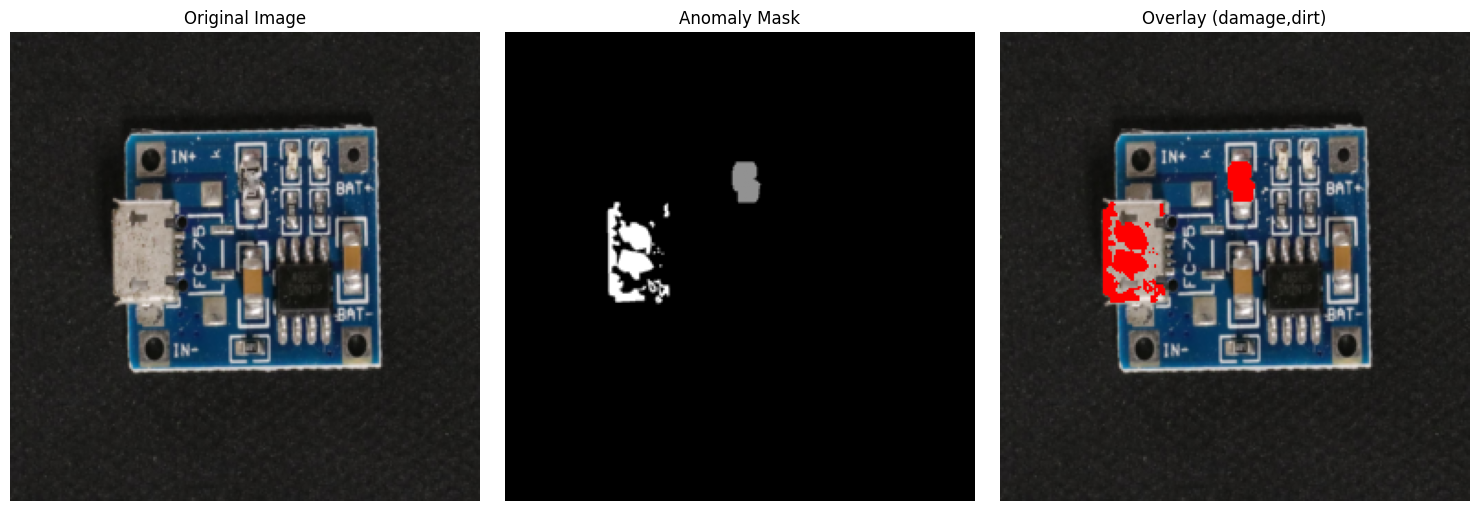

In [13]:
visualize_with_mask(test_loader.dataset, 210)

210번(damage,dirt)에 마스크를 겹쳐 보니 왼쪽 USB 커넥터 쪽이랑 위쪽 작은 부분이 결함이었다. 사진만 봐서는 잘 안 보이던 곳이다.

`Clipping input data` 경고는 0 ~ 1 이미지에 빨간색을 255로 넣어서 뜬 건데, 1로 잘려서 그림은 제대로 나왔다.

## 모델 구현

### 세 방법 정리 (강의랑 코드 보고 이해한 대로)

| 방법 | 정상 이미지로 배우는 것 | 이상 점수 |
|---|---|---|
| PaDiM | 사전학습 Wide ResNet-50 특징으로 28×28 위치마다 평균, 공분산 | 위치별 마할라노비스 거리 중 최댓값 |
| AutoEncoder | 이미지를 압축했다가 다시 복원하는 것 | 원본과 복원 이미지 차이(MSE) |
| One-Class SVM | 이미지 전체 평균 특징을 감싸는 경계 | 경계에서 벗어난 정도 |

PaDiM이랑 OCSVM은 같은 Wide ResNet-50(layer2, layer3) 특징을 쓰고 CNN은 학습하지 않는다. 학습하는 건 AE뿐이다. PaDiM은 1,536차원을 랜덤 행렬로 100차원까지 줄여서 계산한다.

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, roc_curve
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

import cv2
from PIL import Image
from pathlib import Path
import pickle
import json
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# GPU 설정
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"사용 장치: {device}")


사용 장치: cuda


In [15]:
class FeatureExtractor(nn.Module):
    def __init__(self, model_name='resnet18', layers_to_extract=['layer1', 'layer2', 'layer3']):
        super(FeatureExtractor, self).__init__()

        if model_name == 'resnet18':
            self.model = models.resnet18(pretrained=True)
        elif model_name == 'resnet50':
            self.model = models.resnet50(pretrained=True)
        elif model_name == 'wide_resnet50':
            self.model = models.wide_resnet50_2(pretrained=True)
        else:
            raise ValueError(f"지원하지 않는 모델: {model_name}")

        self.layers_to_extract = layers_to_extract
        self.features = {}

        # Hook 등록
        for name, module in self.model.named_modules():
            if name in layers_to_extract:
                module.register_forward_hook(self.save_features(name))

        # 평가 모드로 설정
        self.model.eval()

        # 그래디언트 계산 비활성화
        for param in self.model.parameters():
            param.requires_grad = False

    def save_features(self, name):
        def hook(module, input, output):
            self.features[name] = output
        return hook

    def forward(self, x):
        self.features.clear()
        _ = self.model(x)
        return self.features

# Feature Extractor 초기화
feature_extractor = FeatureExtractor('wide_resnet50', ['layer2', 'layer3']).to(device)

Downloading: "https://download.pytorch.org/models/wide_resnet50_2-95faca4d.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-95faca4d.pth


100%|██████████| 132M/132M [00:00<00:00, 158MB/s]


In [16]:
class PaDiM:
    def __init__(self, feature_extractor, d_reduced=100):
        self.feature_extractor = feature_extractor
        self.d_reduced = d_reduced
        self.means = []
        self.inv_covariances = []
        self.projection_matrix = None

    def fit(self, train_loader):
        """정상 데이터로 모델 훈련"""
        print("PaDiM 훈련 시작...")

        # 모든 훈련 데이터에서 특징 추출
        all_features = []

        for batch in tqdm(train_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                features = self.feature_extractor(images)

                # 각 이미지별로 처리
                for i in range(images.size(0)):
                    img_features = []

                    # 레이어별 특징 추출 및 결합
                    for layer_name, feat in features.items():
                        # 단일 이미지 특징 추출
                        single_feat = feat[i:i+1]  # [1, C, H, W]

                        # 28x28로 리사이즈
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (28, 28))

                        # 패치별 특징으로 변환 [784, C]
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(28*28, -1)
                        img_features.append(feat_patches)

                    # 레이어별 특징 결합 [784, total_channels]
                    combined_features = torch.cat(img_features, dim=1)
                    all_features.append(combined_features)

        # 모든 특징을 하나로 결합 [N*784, total_channels]
        all_features = torch.cat(all_features, dim=0)
        print(f"전체 특징 크기: {all_features.shape}")

        # 차원 축소를 위한 Random Projection 행렬 생성
        if all_features.shape[1] > self.d_reduced:
            self.projection_matrix = torch.randn(all_features.shape[1], self.d_reduced).to(device)
            # 정규화
            self.projection_matrix = F.normalize(self.projection_matrix, dim=0)

            # 차원 축소 적용
            all_features = torch.mm(all_features, self.projection_matrix)
            print(f"차원 축소 후 크기: {all_features.shape}")

        # 패치 위치별로 분리하여 통계 계산
        n_samples = len(all_features) // (28 * 28)

        for patch_idx in range(28 * 28):
            # 특정 패치 위치의 모든 특징 추출
            patch_features = all_features[patch_idx::28*28]  # [n_samples, d_reduced]

            # 평균과 공분산 계산
            mean = torch.mean(patch_features, dim=0)

            # 공분산 행렬 계산 (정규화 추가)
            centered_features = patch_features - mean
            cov = torch.mm(centered_features.T, centered_features) / (patch_features.shape[0] - 1)

            # 수치 안정성을 위한 정규화
            cov += torch.eye(cov.shape[0]).to(device) * 1e-4

            # 역행렬 계산
            try:
                inv_cov = torch.linalg.inv(cov)
            except:
                # 특이행렬인 경우 pseudo-inverse 사용
                inv_cov = torch.linalg.pinv(cov)

            self.means.append(mean)
            self.inv_covariances.append(inv_cov)

        print(f"PaDiM 훈련 완료! (패치 수: {len(self.means)})")

    def predict(self, test_loader):
        """테스트 데이터에 대한 이상 점수 계산"""
        anomaly_scores = []

        for batch in tqdm(test_loader, desc="이상 탐지 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                features = self.feature_extractor(images)

                # 각 이미지별로 처리
                for i in range(images.size(0)):
                    img_features = []

                    # 레이어별 특징 추출 및 결합
                    for layer_name, feat in features.items():
                        single_feat = feat[i:i+1]
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (28, 28))
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(28*28, -1)
                        img_features.append(feat_patches)

                    combined_features = torch.cat(img_features, dim=1)

                    # 차원 축소 (훈련 시와 동일한 방식)
                    if self.projection_matrix is not None:
                        combined_features = torch.mm(combined_features, self.projection_matrix)

                    # 각 패치별 Mahalanobis 거리 계산
                    patch_scores = []
                    for patch_idx in range(28 * 28):
                        diff = combined_features[patch_idx] - self.means[patch_idx]

                        # Mahalanobis 거리 계산
                        mahal_dist = torch.sqrt(torch.mm(
                            torch.mm(diff.unsqueeze(0), self.inv_covariances[patch_idx]),
                            diff.unsqueeze(1)
                        )).item()

                        patch_scores.append(mahal_dist)

                    # 전체 이상 점수 (최대값 사용)
                    anomaly_scores.append(max(patch_scores))

        return np.array(anomaly_scores), None

In [17]:
class ConvAutoEncoder(nn.Module):
    def __init__(self, input_channels=3, latent_dim=128):
        super(ConvAutoEncoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(input_channels, 32, 4, stride=2, padding=1),  # 128x128
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1),  # 64x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 128, 4, stride=2, padding=1),  # 32x32
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 256, 4, stride=2, padding=1),  # 16x16
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, latent_dim, 4, stride=2, padding=1),  # 8x8
            nn.BatchNorm2d(latent_dim),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 256, 4, stride=2, padding=1),  # 16x16
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1),  # 32x32
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),  # 64x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),  # 128x128
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.ConvTranspose2d(32, input_channels, 4, stride=2, padding=1),  # 256x256
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

class AutoEncoderAnomalyDetector:
    def __init__(self, input_size=(256, 256), latent_dim=128):
        self.model = ConvAutoEncoder(input_channels=3, latent_dim=latent_dim).to(device)
        self.criterion = nn.MSELoss()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=0.001)
        self.input_size = input_size

    def fit(self, train_loader, epochs=50):
        """AutoEncoder 훈련"""
        print("AutoEncoder 훈련 시작...")
        self.model.train()

        train_losses = []

        for epoch in range(epochs):
            epoch_loss = 0
            for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
                images = batch['image'].to(device)

                self.optimizer.zero_grad()
                reconstructed = self.model(images)
                loss = self.criterion(reconstructed, images)
                loss.backward()
                self.optimizer.step()

                epoch_loss += loss.item()

            avg_loss = epoch_loss / len(train_loader)
            train_losses.append(avg_loss)
            print(f"Epoch {epoch+1}, Loss: {avg_loss:.6f}")

        self.model.eval()
        print("AutoEncoder 훈련 완료!")
        return train_losses

    def predict(self, test_loader):
        """테스트 데이터에 대한 재구성 오차 계산"""
        self.model.eval()
        anomaly_scores = []

        with torch.no_grad():
            for batch in tqdm(test_loader, desc="이상 탐지 중"):
                images = batch['image'].to(device)
                reconstructed = self.model(images)

                # 픽셀별 재구성 오차
                reconstruction_errors = F.mse_loss(reconstructed, images, reduction='none')
                reconstruction_errors = reconstruction_errors.view(images.size(0), -1).mean(dim=1)

                anomaly_scores.extend(reconstruction_errors.cpu().numpy())

        return np.array(anomaly_scores)

In [18]:
class OneClassSVMAnomalyDetector:
    def __init__(self, feature_extractor, nu=0.1):
        self.feature_extractor = feature_extractor
        self.svm = OneClassSVM(nu=nu, kernel='rbf', gamma='scale')
        self.scaler = StandardScaler()

    def extract_features(self, data_loader):
        """특징 추출"""
        features = []

        for batch in tqdm(data_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)

            with torch.no_grad():
                feat_dict = self.feature_extractor(images)

                # 모든 레이어의 특징을 결합하고 평균 풀링
                combined_features = []
                for layer_name, feat in feat_dict.items():
                    pooled_feat = F.adaptive_avg_pool2d(feat, (1, 1))
                    combined_features.append(pooled_feat.view(feat.size(0), -1))

                batch_features = torch.cat(combined_features, dim=1)
                features.append(batch_features.cpu().numpy())

        return np.concatenate(features, axis=0)

    def fit(self, train_loader):
        """One-Class SVM 훈련"""
        print("One-Class SVM 훈련 시작...")

        # 특징 추출
        train_features = self.extract_features(train_loader)

        # 정규화
        train_features_scaled = self.scaler.fit_transform(train_features)

        # SVM 훈련
        self.svm.fit(train_features_scaled)
        print("One-Class SVM 훈련 완료!")

    def predict(self, test_loader):
        """테스트 데이터에 대한 이상 점수 계산"""
        # 특징 추출
        test_features = self.extract_features(test_loader)

        # 정규화
        test_features_scaled = self.scaler.transform(test_features)

        # 이상 점수 계산 (결정 함수의 음수)
        anomaly_scores = -self.svm.decision_function(test_features_scaled)

        return anomaly_scores

In [19]:
class AnomalyDetectionEvaluator:
    def __init__(self):
        self.results = {}

    def evaluate(self, y_true, y_scores, method_name):
        """평가 메트릭 계산"""
        # AUROC
        auroc = roc_auc_score(y_true, y_scores)

        # AUPRC
        precision, recall, thresholds = precision_recall_curve(y_true, y_scores)
        auprc = auc(recall, precision)

        # 최적 임계값에서의 F1 스코어
        f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

        # NaN 값 제거
        valid_indices = ~np.isnan(f1_scores)
        if np.any(valid_indices):
            valid_f1_scores = f1_scores[valid_indices]
            valid_thresholds = thresholds[valid_indices] if len(thresholds) == len(f1_scores) else thresholds[:len(valid_f1_scores)]

            best_f1_idx = np.argmax(valid_f1_scores)
            best_f1 = valid_f1_scores[best_f1_idx]
            best_threshold = valid_thresholds[best_f1_idx] if len(valid_thresholds) > best_f1_idx else 0.5
        else:
            best_f1 = 0.0
            best_threshold = 0.5

        self.results[method_name] = {
            'AUROC': auroc,
            'AUPRC': auprc,
            'Best_F1': best_f1,
            'Best_Threshold': best_threshold,
            'y_true': y_true,
            'y_scores': y_scores
        }

        print(f"{method_name} 결과:")
        print(f"  AUROC: {auroc:.4f}")
        print(f"  AUPRC: {auprc:.4f}")
        print(f"  Best F1: {best_f1:.4f}")
        print()

        return auroc, auprc, best_f1

    def plot_roc_curve(self):
        """ROC 곡선 그리기"""
        plt.figure(figsize=(10, 8))

        for method_name, result in self.results.items():
            fpr, tpr, _ = roc_curve(result['y_true'], result['y_scores'])
            plt.plot(fpr, tpr, label=f"{method_name} (AUC = {result['AUROC']:.3f})")

        plt.plot([0, 1], [0, 1], 'k--', label='Random')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('ROC Curves Comparison')
        plt.legend()
        plt.grid(True)
        plt.show()

    def plot_precision_recall_curve(self):
        """PR 곡선 그리기"""
        plt.figure(figsize=(10, 8))

        for method_name, result in self.results.items():
            precision, recall, _ = precision_recall_curve(result['y_true'], result['y_scores'])
            plt.plot(recall, precision, label=f"{method_name} (AUC = {result['AUPRC']:.3f})")

        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title('Precision-Recall Curves Comparison')
        plt.legend()
        plt.grid(True)
        plt.show()

    def plot_score_distribution(self):
        """이상 점수 분포 시각화"""
        fig, axes = plt.subplots(len(self.results), 1, figsize=(12, 4*len(self.results)))
        if len(self.results) == 1:
            axes = [axes]

        for i, (method_name, result) in enumerate(self.results.items()):
            normal_scores = result['y_scores'][result['y_true'] == 0]
            anomaly_scores = result['y_scores'][result['y_true'] == 1]

            axes[i].hist(normal_scores, bins=50, alpha=0.7, label='Normal', density=True)
            axes[i].hist(anomaly_scores, bins=50, alpha=0.7, label='Anomaly', density=True)
            axes[i].axvline(result['Best_Threshold'], color='red', linestyle='--',
                           label=f"Best Threshold: {result['Best_Threshold']:.3f}")
            axes[i].set_title(f'{method_name} - Anomaly Score Distribution')
            axes[i].set_xlabel('Anomaly Score')
            axes[i].set_ylabel('Density')
            axes[i].legend()
            axes[i].grid(True)

        plt.tight_layout()
        plt.show()

    def compare_methods(self):
        """방법별 성능 비교"""
        methods = list(self.results.keys())
        aurocs = [self.results[m]['AUROC'] for m in methods]
        auprcs = [self.results[m]['AUPRC'] for m in methods]
        f1_scores = [self.results[m]['Best_F1'] for m in methods]

        x = np.arange(len(methods))
        width = 0.25

        plt.figure(figsize=(12, 6))
        plt.bar(x - width, aurocs, width, label='AUROC', alpha=0.8)
        plt.bar(x, auprcs, width, label='AUPRC', alpha=0.8)
        plt.bar(x + width, f1_scores, width, label='Best F1', alpha=0.8)

        plt.xlabel('Methods')
        plt.ylabel('Score')
        plt.title('Performance Comparison')
        plt.xticks(x, methods, rotation=45)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

In [20]:
class VisAAnomalyDetectionSystem:
    def __init__(self, data_path, category):
        self.data_path = data_path
        self.category = category
        self.evaluator = AnomalyDetectionEvaluator()

        # 데이터 로더 생성
        self.train_loader, self.test_loader = create_visa_data_loaders(
            data_path, category, batch_size=16, include_mask=False, train_ratio=0.8
        )

        # 테스트 레이블 추출
        self.test_labels = []
        for batch in self.test_loader:
            self.test_labels.extend(batch['label'].numpy())
        self.test_labels = np.array(self.test_labels)

        print(f"시스템 초기화 완료:")
        print(f"  카테고리: {category}")
        print(f"  훈련 데이터: {len(self.train_loader.dataset)}개")
        print(f"  테스트 데이터: {len(self.test_loader.dataset)}개")
        print(f"  테스트 중 이상 데이터: {self.test_labels.sum()}개")

    def run_padim(self):
        """PaDiM 실행"""
        print("\n=== PaDiM 실행 ===")
        padim = PaDiM(feature_extractor, d_reduced=100)
        padim.fit(self.train_loader)
        scores, _ = padim.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'PaDiM')
        return scores

    def run_autoencoder(self, epochs=30):
        """AutoEncoder 실행"""
        print("\n=== AutoEncoder 실행 ===")
        ae_detector = AutoEncoderAnomalyDetector()
        ae_detector.fit(self.train_loader, epochs=epochs)
        scores = ae_detector.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'AutoEncoder')
        return scores

    def run_ocsvm(self):
        """One-Class SVM 실행"""
        print("\n=== One-Class SVM 실행 ===")
        ocsvm_detector = OneClassSVMAnomalyDetector(feature_extractor, nu=0.1)
        ocsvm_detector.fit(self.train_loader)
        scores = ocsvm_detector.predict(self.test_loader)
        self.evaluator.evaluate(self.test_labels, scores, 'One-Class SVM')
        return scores

    def run_all_methods(self):
        """모든 방법 실행 및 비교"""
        print("모든 anomaly detection 방법을 실행합니다...")

        # 각 방법 실행 (오류가 발생해도 계속 진행)
        methods_tried = []

        # 1. AutoEncoder (가장 안정적)
        try:
            print("\n=== AutoEncoder 실행 ===")
            self.run_autoencoder(epochs=15)
            methods_tried.append("AutoEncoder")
        except Exception as e:
            print(f"AutoEncoder 실행 중 오류: {e}")

        # 2. One-Class SVM
        try:
            print("\n=== One-Class SVM 실행 ===")
            self.run_ocsvm()
            methods_tried.append("One-Class SVM")
        except Exception as e:
            print(f"One-Class SVM 실행 중 오류: {e}")

        # 3. PaDiM (메모리 사용량이 많을 수 있음)
        try:
            print("\n=== PaDiM 실행 ===")
            self.run_padim()
            methods_tried.append("PaDiM")
        except Exception as e:
            print(f"PaDiM 실행 중 오류: {e}")
            print("팁: GPU 메모리가 부족할 수 있습니다. 배치 크기를 줄여보세요.")

        # 결과 시각화
        if self.evaluator.results:
            print(f"\n=== 전체 결과 ({len(methods_tried)}개 방법 성공) ===")
            try:
                self.evaluator.compare_methods()
            except Exception as e:
                print(f"비교 차트 생성 중 오류: {e}")

            try:
                self.evaluator.plot_roc_curve()
            except Exception as e:
                print(f"ROC 곡선 생성 중 오류: {e}")

            try:
                self.evaluator.plot_precision_recall_curve()
            except Exception as e:
                print(f"PR 곡선 생성 중 오류: {e}")

            try:
                self.evaluator.plot_score_distribution()
            except Exception as e:
                print(f"점수 분포 차트 생성 중 오류: {e}")
        else:
            print("❌ 성공적으로 실행된 방법이 없습니다.")
            print("다음을 확인해보세요:")
            print("1. 데이터 경로가 올바른지 확인")
            print("2. GPU 메모리가 충분한지 확인")
            print("3. 필요한 라이브러리가 모두 설치되어 있는지 확인")

    def save_results(self, filename):
        """결과 저장"""
        results_to_save = {}
        for method, result in self.evaluator.results.items():
            results_to_save[method] = {
                'AUROC': result['AUROC'],
                'AUPRC': result['AUPRC'],
                'Best_F1': result['Best_F1'],
                'Best_Threshold': result['Best_Threshold']
            }

        with open(filename, 'w') as f:
            json.dump(results_to_save, f, indent=2)
        print(f"결과가 {filename}에 저장되었습니다.")

In [21]:
system = VisAAnomalyDetectionSystem("./VisA", "pcb4")

# 개별 방법 실행
padim_scores = system.run_padim()
ae_scores = system.run_autoencoder(epochs=50)
svm_scores = system.run_ocsvm()


CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개
시스템 초기화 완료:
  카테고리: pcb4
  훈련 데이터: 804개
  테스트 데이터: 301개
  테스트 중 이상 데이터: 100개

=== PaDiM 실행 ===
PaDiM 훈련 시작...


특징 추출 중: 100%|██████████| 51/51 [00:15<00:00,  3.37it/s]


전체 특징 크기: torch.Size([630336, 1536])
차원 축소 후 크기: torch.Size([630336, 100])
PaDiM 훈련 완료! (패치 수: 784)


이상 탐지 중: 100%|██████████| 19/19 [00:26<00:00,  1.37s/it]


PaDiM 결과:
  AUROC: 0.9668
  AUPRC: 0.9159
  Best F1: 0.9005


=== AutoEncoder 실행 ===
AutoEncoder 훈련 시작...


...

AutoEncoder 결과:
  AUROC: 0.2660
  AUPRC: 0.2262
  Best F1: 0.5249


=== One-Class SVM 실행 ===
One-Class SVM 훈련 시작...


특징 추출 중: 100%|██████████| 51/51 [00:14<00:00,  3.49it/s]


One-Class SVM 훈련 완료!


특징 추출 중: 100%|██████████| 19/19 [00:05<00:00,  3.61it/s]


One-Class SVM 결과:
  AUROC: 0.8182
  AUPRC: 0.7065
  Best F1: 0.6590



### 결과 (테스트 301장: 정상 201 / 불량 100)

| 방법 | AUROC | AUPRC | Best F1 |
|---|---:|---:|---:|
| PaDiM | 0.9668 | 0.9159 | 0.9005 |
| AutoEncoder | 0.2660 | 0.2262 | 0.5249 |
| One-Class SVM | 0.8182 | 0.7065 | 0.6590 |

PaDiM이 세 지표 다 제일 높다. 위치마다 정상 분포를 따로 잡으니까 부품 누락 같은 작은 차이도 잡히는 것 같다. OCSVM은 같은 특징인데 이미지 전체를 평균 내서 벡터 하나로 만들어서 작은 결함이 묻히는 듯하다.

AE는 AUROC가 0.5도 안 된다. 랜덤보다 못한 거라 뭔가 잘못된 것 같다. loss도 2.31에서 시작해서 1.64 근처에서 더 안 내려갔다. 아래에서 따로 확인했다.

Best F1은 테스트셋에서 제일 좋은 임계값을 골라서 낸 값이라 실제로 쓰면 이보다 낮을 거다.

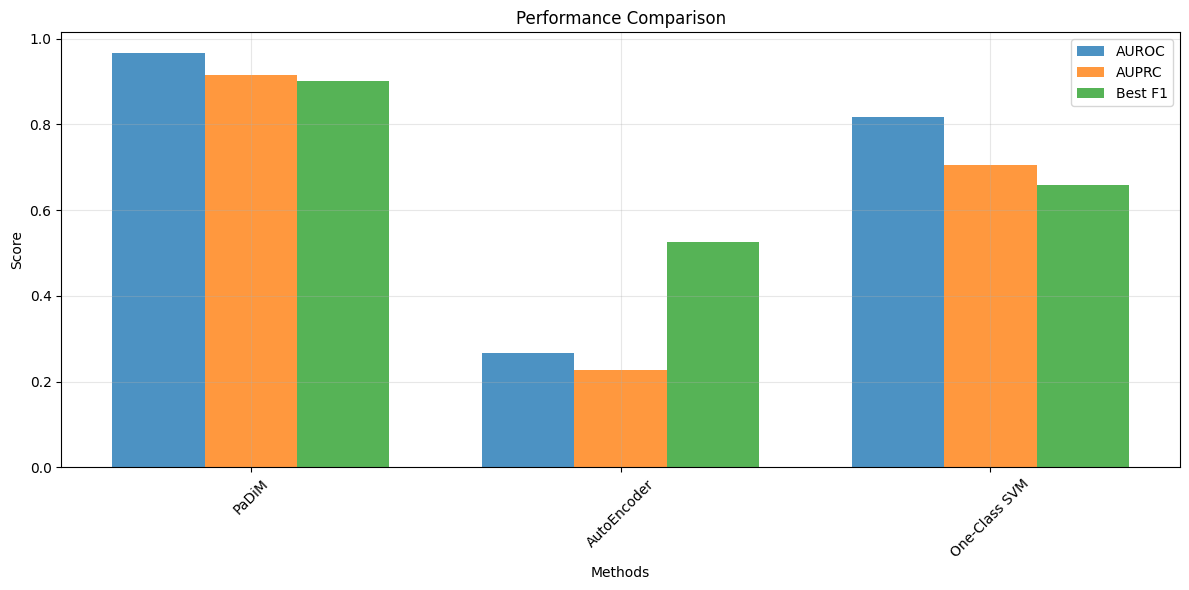

In [22]:
system.evaluator.compare_methods()

막대그래프로 보면 PaDiM은 세 지표 다 0.9 넘고, AE는 AUROC랑 AUPRC가 0.3도 안 된다. AE의 Best F1(0.52)만 조금 높게 나왔는데, 아래 PR 곡선을 보면 recall 1, 즉 불량을 다 잡는 대신 정상도 대부분 불량으로 판정하는 임계값에서 나온 값이라 의미는 없다.

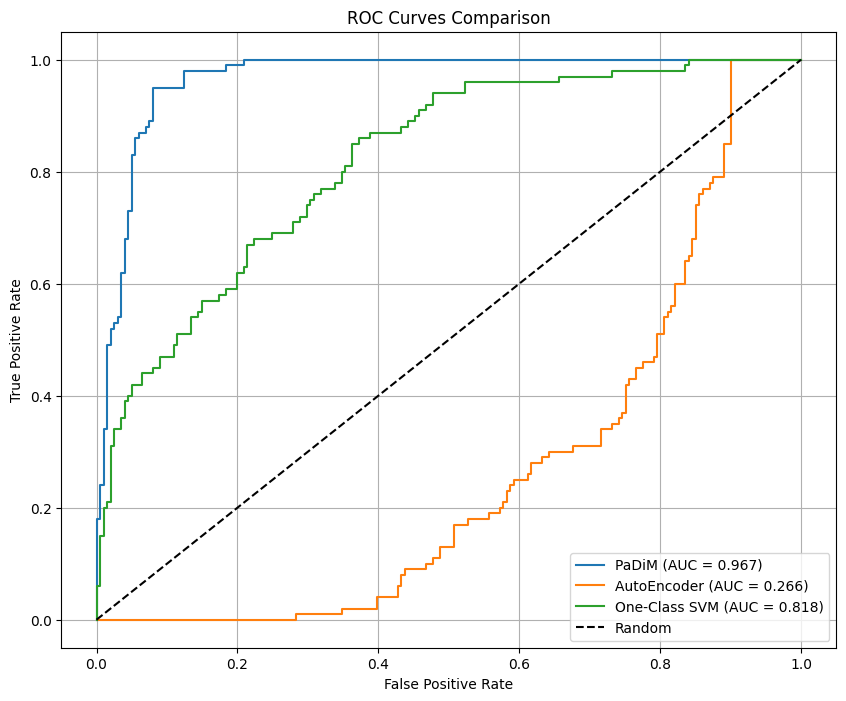

In [23]:
system.evaluator.plot_roc_curve()

ROC를 보면 PaDiM은 FPR 0.1 안쪽에서 TPR이 0.95까지 올라간다. OCSVM은 그보다 완만하게 올라가고, AE는 대각선 아래라 랜덤보다 못하다.

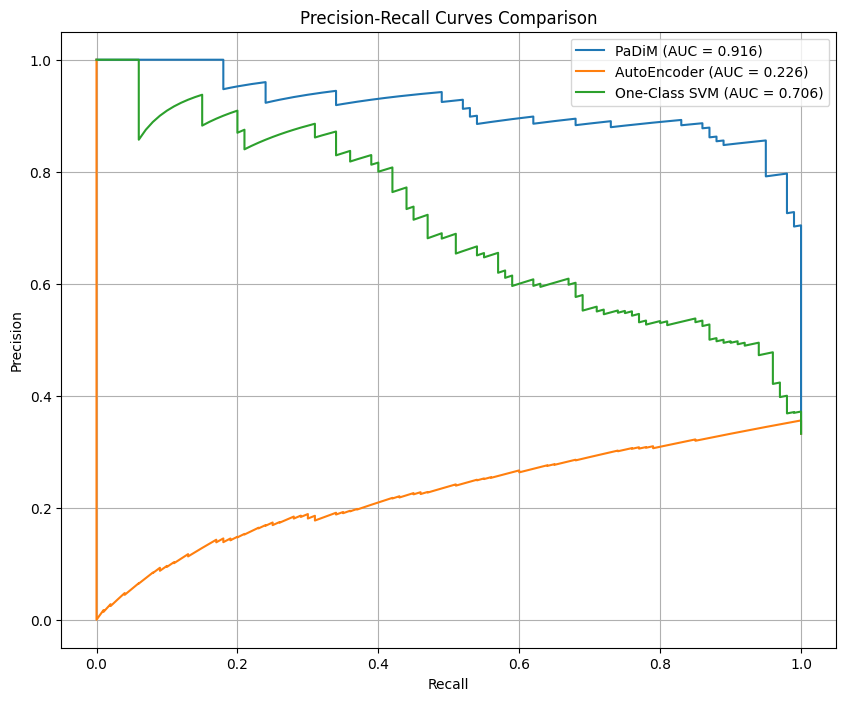

In [24]:
system.evaluator.plot_precision_recall_curve()

PR 곡선도 순서가 같다. PaDiM은 recall 0.95 근처까지 precision 0.85 이상을 유지하는데 OCSVM은 recall이 올라갈수록 계속 떨어진다. AE는 recall이 커질수록 precision이 오히려 올라가는 거꾸로 된 모양이다.

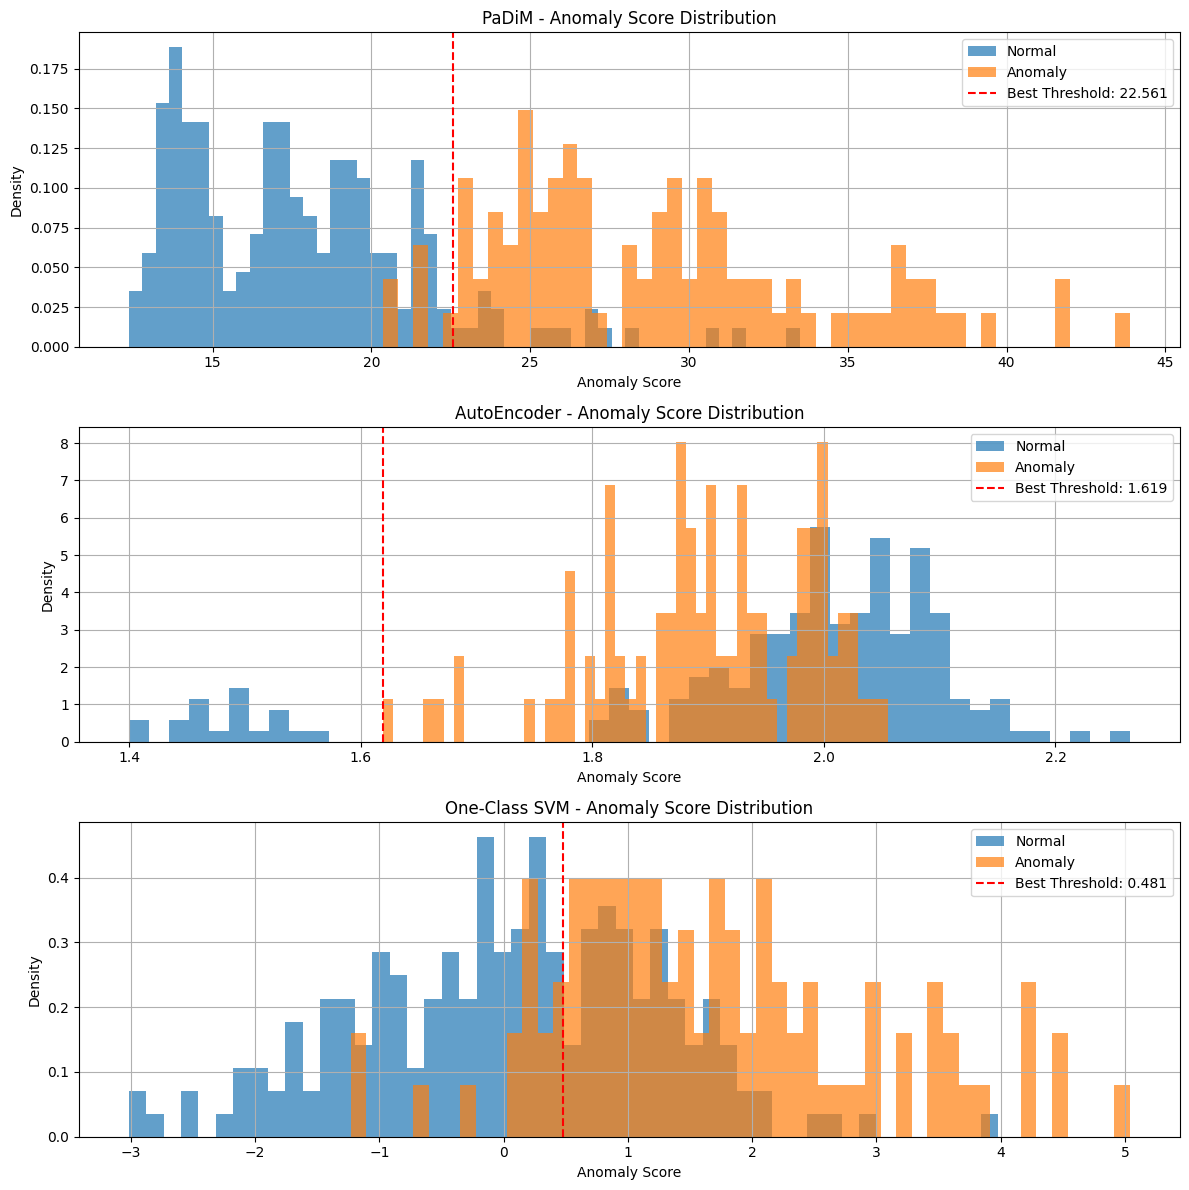

In [25]:
system.evaluator.plot_score_distribution()

점수 분포를 보면 PaDiM은 정상(파란색)이 대부분 12 ~ 22, 불량(주황색)이 21 ~ 44에 있어서 거의 갈린다. 다만 정상 몇 장은 25 ~ 33까지 올라가서 불량 쪽에 섞여 있다. 평균은 정상 17.77, 불량 28.93이다.

AE는 정상 대부분이 1.9 ~ 2.2에 있어서 불량(1.8 ~ 2.05)보다 오른쪽에 있다. 정상이 더 이상하다고 나오는 거라 분포가 거꾸로다. 1.4 ~ 1.6에 따로 모인 정상 몇 장만 불량보다 낮았다. OCSVM은 0 ~ 2 구간에서 정상이랑 불량이 많이 겹친다.

In [37]:
# (추가) AE AUROC가 0.5보다 낮아서 원인 확인
# AE 출력은 Sigmoid(0~1)인데 입력은 ImageNet 정규화된 값이라 범위가 맞는지 확인
x = next(iter(system.test_loader))['image']
print(f'정규화된 입력 값 범위(테스트 첫 배치 16장): {x.min().item():.2f} ~ {x.max().item():.2f}')
print(f'0~1 범위를 벗어난 값의 비율: {((x < 0) | (x > 1)).float().mean().item():.1%}  -> Sigmoid 출력으로는 만들 수 없는 값')

labels = system.test_labels
print(f'AutoEncoder 점수 평균 - 정상: {ae_scores[labels == 0].mean():.4f} / 불량: {ae_scores[labels == 1].mean():.4f}')
print(f'PaDiM 점수 평균 - 정상: {padim_scores[labels == 0].mean():.2f} / 불량: {padim_scores[labels == 1].mean():.2f}')

정규화된 입력 값 범위(테스트 첫 배치 16장): -2.10 ~ 2.64
0~1 범위를 벗어난 값의 비율: 90.9%  -> Sigmoid 출력으로는 만들 수 없는 값
AutoEncoder 점수 평균 - 정상: 1.9584 / 불량: 1.8993
PaDiM 점수 평균 - 정상: 17.77 / 불량: 28.93


### AE가 왜 랜덤보다 낮은지 확인

AE 마지막 층이 Sigmoid라서 출력은 0 ~ 1밖에 안 나온다. 그런데 입력은 ImageNet 평균/표준편차로 정규화해서 -2.10 ~ 2.64이고, 0 ~ 1을 벗어나는 값이 90.9%다. 애초에 복원이 안 되는 구조라 loss가 1.64에서 멈춘 것 같다.

정상 평균 점수(1.9584)가 불량(1.8993)보다 높았다. 결함보다 밝기 같은 다른 차이에 더 반응하는 것 같은데 여기서는 확인을 못 했다.

정규화를 빼거나 Sigmoid를 없애면 될 것 같아서, 뒤 추가 분석(B, E)에서 입력을 0 ~ 1로 바꿔 다시 학습해봤다. (나중에 E-1에서 보니 테스트 정상 이미지가 학습 이미지보다 어두운 것도 원인이었다.)

### 실시간 inference

In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import cv2
import numpy as np
import torchvision.models as models

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, roc_curve
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

import cv2
from PIL import Image
from pathlib import Path
import pickle
import json
from tqdm import tqdm
import warnings

In [27]:
class VisADataset(Dataset):
    def __init__(self, data_path, category, transform=None, is_train=True, include_mask=False, train_ratio=0.8):
        self.data_path = Path(data_path)
        self.category = category
        self.transform = transform
        self.is_train = is_train
        self.include_mask = include_mask

        self.image_paths = []
        self.mask_paths = []
        self.labels = []
        self.defect_types = []

        category_path = self.data_path / category

        # CSV 파일에서 메타데이터 로드
        csv_path = category_path / "image_anno.csv"
        if csv_path.exists():
            df = pd.read_csv(csv_path)
            print(f"CSV 컬럼: {df.columns.tolist()}")

            # 정상/비정상 데이터 분리
            normal_df = df[df['label'] == 'normal'].copy()
            anomaly_df = df[df['label'] != 'normal'].copy()

            if self.is_train:
                # 훈련용: 정상 데이터의 일부만 사용
                train_size = int(len(normal_df) * train_ratio)
                selected_df = normal_df.iloc[:train_size]
                print(f"훈련용 정상 데이터: {len(selected_df)}개")
            else:
                # 테스트용: 나머지 정상 데이터 + 모든 비정상 데이터
                test_normal_size = len(normal_df) - int(len(normal_df) * train_ratio)
                test_normal_df = normal_df.iloc[-test_normal_size:] if test_normal_size > 0 else pd.DataFrame()
                selected_df = pd.concat([test_normal_df, anomaly_df], ignore_index=True)
                print(f"테스트용 정상 데이터: {len(test_normal_df)}개")
                print(f"테스트용 비정상 데이터: {len(anomaly_df)}개")

            # 데이터 로드
            for _, row in selected_df.iterrows():
                # 이미지 경로 처리 (중복 경로 제거)
                image_rel_path = row['image']
                if image_rel_path.startswith(category + '/'):
                    image_path = self.data_path / image_rel_path
                else:
                    image_path = category_path / image_rel_path

                if image_path.exists():
                    self.image_paths.append(str(image_path))
                    self.labels.append(0 if row['label'] == 'normal' else 1)
                    self.defect_types.append(row['label'])

                    # 마스크 경로 처리
                    if pd.notna(row['mask']) and self.include_mask:
                        mask_rel_path = row['mask']
                        if mask_rel_path.startswith(category + '/'):
                            mask_path = self.data_path / mask_rel_path
                        else:
                            mask_path = category_path / mask_rel_path
                        self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                    else:
                        self.mask_paths.append(None)
                else:
                    print(f"이미지 파일을 찾을 수 없습니다: {image_path}")
        else:
            print("CSV 파일이 없습니다. 폴더 구조를 기반으로 데이터를 로드합니다.")
            self._load_from_folder_structure()

    def _load_from_folder_structure(self):
        """폴더 구조를 기반으로 데이터 로드 (CSV가 없는 경우)"""
        category_path = self.data_path / self.category
        images_path = category_path / "Data" / "Images"
        masks_path = category_path / "Data" / "Masks"

        if self.is_train:
            # 훈련용: 정상 이미지만 사용
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)  # 정상: 0
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)
        else:
            # 테스트용: 정상 + 비정상 이미지
            # 정상 이미지
            normal_path = images_path / "Normal"
            if normal_path.exists():
                for img_path in normal_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(0)
                        self.defect_types.append('normal')
                        self.mask_paths.append(None)

            # 비정상 이미지
            anomaly_path = images_path / "Anomaly"
            if anomaly_path.exists():
                for img_path in anomaly_path.glob("*"):
                    if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
                        self.image_paths.append(str(img_path))
                        self.labels.append(1)  # 이상: 1
                        self.defect_types.append('anomaly')

                        # 마스크 경로 찾기
                        if self.include_mask:
                            mask_name = img_path.stem + '.png'  # 확장자를 png로 변경
                            mask_path = masks_path / "Anomaly" / mask_name
                            self.mask_paths.append(str(mask_path) if mask_path.exists() else None)
                        else:
                            self.mask_paths.append(None)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # 이미지 로드
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]

        # 마스크 로드 (있는 경우)
        mask = None
        if self.include_mask and self.mask_paths[idx] is not None:
            try:
                mask = Image.open(self.mask_paths[idx]).convert('L')
            except:
                mask = None

        # 변환 적용
        if self.transform:
            image = self.transform(image)
            if mask is not None:
                mask_transform = transforms.Compose([
                    transforms.Resize((256, 256)),
                    transforms.ToTensor()
                ])
                mask = mask_transform(mask)

        result = {
            'image': image,
            'label': label,
            'defect_type': self.defect_types[idx]
        }

        if mask is not None:
            result['mask'] = mask

        return result

In [28]:
def create_visa_data_loaders(data_path, category, batch_size=32, include_mask=False, train_ratio=0.8):
    """
    VisA 데이터셋용 데이터 로더 생성

    Args:
        data_path: VisA 데이터셋 경로
        category: 카테고리 이름
        batch_size: 배치 크기
        include_mask: 마스크 포함 여부
        train_ratio: 훈련 데이터 비율 (정상 데이터에서)
    """
    train_transform, test_transform = get_visa_transforms()

    train_dataset = VisADataset(
        data_path, category,
        transform=train_transform,
        is_train=True,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    test_dataset = VisADataset(
        data_path, category,
        transform=test_transform,
        is_train=False,
        include_mask=include_mask,
        train_ratio=train_ratio
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,  # Windows에서 문제가 있을 수 있으므로 낮춤
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    return train_loader, test_loader


In [29]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [30]:
class FeatureExtractor(nn.Module):
    def __init__(self, model_name='resnet18', layers_to_extract=['layer1', 'layer2', 'layer3']):
        super(FeatureExtractor, self).__init__()

        if model_name == 'resnet18':
            self.model = models.resnet18(pretrained=True)
        elif model_name == 'resnet50':
            self.model = models.resnet50(pretrained=True)
        elif model_name == 'wide_resnet50':
            self.model = models.wide_resnet50_2(pretrained=True)
        else:
            raise ValueError(f"지원하지 않는 모델: {model_name}")

        self.layers_to_extract = layers_to_extract
        self.features = {}

        # Hook 등록
        for name, module in self.model.named_modules():
            if name in layers_to_extract:
                module.register_forward_hook(self.save_features(name))

        # 평가 모드로 설정
        self.model.eval()

        # 그래디언트 계산 비활성화
        for param in self.model.parameters():
            param.requires_grad = False

    def save_features(self, name):
        def hook(module, input, output):
            self.features[name] = output
        return hook

    def forward(self, x):
        self.features.clear()
        _ = self.model(x)
        return self.features

# Feature Extractor 초기화
feature_extractor = FeatureExtractor('wide_resnet50', ['layer2', 'layer3']).to(device)


In [31]:
# --- PaDiM 클래스 (사용자 제공 코드, predict 수정) ---
class PaDiM:
    def __init__(self, feature_extractor, d_reduced=100, padim_patch_size=PADIM_PATCH_SIZE):
        self.feature_extractor = feature_extractor
        self.d_reduced = d_reduced
        self.padim_patch_size = padim_patch_size
        self.means = []
        self.inv_covariances = []
        self.projection_matrix = None

    def fit(self, train_loader):
        print("PaDiM 훈련 시작...")
        all_features = []
        for batch in tqdm(train_loader, desc="특징 추출 중"):
            images = batch['image'].to(device)
            with torch.no_grad():
                features = self.feature_extractor(images)
                for i in range(images.size(0)):
                    img_features = []
                    for layer_name, feat in features.items():
                        single_feat = feat[i:i+1]
                        feat_resized = F.adaptive_avg_pool2d(single_feat, (self.padim_patch_size, self.padim_patch_size))
                        feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(self.padim_patch_size*self.padim_patch_size, -1)
                        img_features.append(feat_patches)
                    combined_features = torch.cat(img_features, dim=1)
                    all_features.append(combined_features)

        all_features = torch.cat(all_features, dim=0)
        print(f"전체 특징 크기: {all_features.shape}")

        if all_features.shape[1] > self.d_reduced:
            self.projection_matrix = torch.randn(all_features.shape[1], self.d_reduced).to(device)
            self.projection_matrix = F.normalize(self.projection_matrix, dim=0)
            all_features = torch.mm(all_features, self.projection_matrix)
            print(f"차원 축소 후 크기: {all_features.shape}")

        num_patches = self.padim_patch_size * self.padim_patch_size
        for patch_idx in range(num_patches):
            patch_features = all_features[patch_idx::num_patches]
            mean = torch.mean(patch_features, dim=0)
            centered_features = patch_features - mean
            cov = torch.mm(centered_features.T, centered_features) / (patch_features.shape[0] - 1)
            cov += torch.eye(cov.shape[0]).to(device) * 1e-4
            try:
                inv_cov = torch.linalg.inv(cov)
            except RuntimeError:
                inv_cov = torch.linalg.pinv(cov)
            self.means.append(mean)
            self.inv_covariances.append(inv_cov)
        print(f"PaDiM 훈련 완료! (패치 수: {len(self.means)})")

    def predict(self, images_tensor): # DataLoader 대신 이미지 텐서를 직접 받도록 수정
        """테스트 이미지 텐서에 대한 이상 점수 및 이상 맵 계산"""
        all_image_scores = []
        all_anomaly_maps = []

        with torch.no_grad():
            features = self.feature_extractor(images_tensor) # 이미지 텐서 바로 사용

            for i in range(images_tensor.size(0)):
                img_features = []
                for layer_name, feat in features.items():
                    single_feat = feat[i:i+1]
                    feat_resized = F.adaptive_avg_pool2d(single_feat, (self.padim_patch_size, self.padim_patch_size))
                    feat_patches = feat_resized.permute(0, 2, 3, 1).reshape(self.padim_patch_size*self.padim_patch_size, -1)
                    img_features.append(feat_patches)

                combined_features = torch.cat(img_features, dim=1)

                if self.projection_matrix is not None:
                    combined_features = torch.mm(combined_features, self.projection_matrix)

                patch_scores_for_image = []
                num_patches = self.padim_patch_size * self.padim_patch_size
                for patch_idx in range(num_patches):
                    diff = combined_features[patch_idx] - self.means[patch_idx]
                    mahal_dist = torch.sqrt(torch.mm(
                        torch.mm(diff.unsqueeze(0), self.inv_covariances[patch_idx]),
                        diff.unsqueeze(1)
                    )).item()
                    patch_scores_for_image.append(mahal_dist)

                all_image_scores.append(max(patch_scores_for_image))

                # 이상 맵 생성 (28x28 형태로)
                anomaly_map = torch.tensor(patch_scores_for_image).reshape(self.padim_patch_size, self.padim_patch_size).cpu().numpy()
                all_anomaly_maps.append(anomaly_map)

        return np.array(all_image_scores), np.array(all_anomaly_maps)

In [32]:
def get_visa_transforms():
    """
    VisA 데이터셋에 적용할 이미지 변환(transform)을 반환합니다.
    실제 데이터셋과 모델에 맞게 이 부분을 수정해야 합니다.
    """
    train_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD)
    ])

    # 테스트 시에는 일반적으로 Augmentation을 많이 하지 않습니다.
    test_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD)
    ])
    return train_transform, test_transform


In [33]:
# --- 데이터셋 경로 및 카테고리 설정 ---
# !!! 중요: 이 경로를 실제 VisA 데이터셋이 있는 경로로 수정해야 합니다 !!!
# 예시: DATA_PATH = "/path/to/your/visa_dataset"
# VisA 데이터셋이 없다면, 아래 예시처럼 직접 폴더를 만들고 소수의 이미지를 넣어 테스트할 수 있습니다.
# DATA_PATH/CATEGORY_NAME/train/good/img1.png, img2.png ...
# DATA_PATH/CATEGORY_NAME/test/good/img1.png, img2.png ...
# DATA_PATH/CATEGORY_NAME/test/anomaly_type1/img1.png, img2.png ...
DATA_PATH = "./VisA" # <--- 실제 데이터셋 경로로 변경하세요!
CATEGORY_NAME = "pcb4" # VisA 데이터셋의 카테고리 중 하나 (예: 'pcb', 'capsules' 등)
BATCH_SIZE = 8 # 메모리에 따라 조절
D_REDUCED = 100 # PaDiM의 축소된 특징 차원
IMG_SIZE = 256  # 입력 이미지 크기 (예시)
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]
# PaDiM 내부에서 특징맵을 리사이즈할 크기 (고정)
PADIM_PATCH_SIZE = 28

# 결과물 저장 경로
OUTPUT_DIR = "padim_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
SAVED_MODEL_PATH = os.path.join(OUTPUT_DIR, "padim_model_state.pkl")

print(f"Data path set to: {DATA_PATH}")
print(f"Make sure you have data in the respective folders, e.g., {os.path.join(DATA_PATH, CATEGORY_NAME, 'train', 'good')}")
print("-" * 30)


# --- 모델 초기화 ---
print("FeatureExtractor 초기화 중...")
# 사용할 CNN 백본과 추출할 레이어 설정
# 예: wide_resnet50_2의 layer1, layer2, layer3 특징 사용
feature_extractor = FeatureExtractor(model_name='wide_resnet50', layers_to_extract=['layer1', 'layer2', 'layer3']).to(device)
print("PaDiM 모델 초기화 중...")
padim_model = PaDiM(feature_extractor=feature_extractor, d_reduced=D_REDUCED)

# --- 데이터 로더 생성 ---
print("데이터 로더 생성 중...")
try:
    train_loader, test_loader = create_visa_data_loaders(DATA_PATH, CATEGORY_NAME, BATCH_SIZE)

    # 훈련 데이터셋에 이미지가 있는지 확인
    if len(train_loader.dataset) == 0:
        print(f"훈련 데이터셋에 이미지가 없습니다! 경로를 확인하세요: {os.path.join(DATA_PATH, CATEGORY_NAME, 'train', 'good')}")
        # 이 경우 학습을 진행할 수 없으므로, 예외를 발생시키거나 중단할 수 있습니다.
        # raise ValueError("훈련 데이터가 비어있습니다. 학습을 진행할 수 없습니다.")
    else:
        print(f"훈련 데이터셋 크기: {len(train_loader.dataset)}")
        print(f"테스트 데이터셋 크기: {len(test_loader.dataset)}")

        # --- PaDiM 모델 학습 ---
        padim_model.fit(train_loader)

        # --- 학습된 모델 저장 ---
        print(f"학습된 PaDiM 모델을 '{SAVED_MODEL_PATH}'에 저장합니다...")
        # PaDiM 클래스 전체를 저장하거나, 필요한 attribute만 저장할 수 있습니다.
        # 여기서는 주요 attribute들을 딕셔너리 형태로 저장합니다.
        padim_state = {
            'means': padim_model.means,
            'inv_covariances': padim_model.inv_covariances,
            'projection_matrix': padim_model.projection_matrix,
            'd_reduced': padim_model.d_reduced,
            'padim_patch_size': padim_model.padim_patch_size
            # FeatureExtractor는 구조가 동일하므로 저장하지 않고 추론 시 새로 생성
        }
        with open(SAVED_MODEL_PATH, 'wb') as f:
            pickle.dump(padim_state, f)
        print("모델 저장 완료.")

except FileNotFoundError as e:
    print(f"데이터 경로 오류: {e}")
    print("DATA_PATH 및 CATEGORY_NAME을 올바르게 설정하고, 해당 경로에 이미지 파일이 있는지 확인해주세요.")
except Exception as e:
    print(f"학습 중 오류 발생: {e}")



Data path set to: ./VisA
Make sure you have data in the respective folders, e.g., ./VisA/pcb4/train/good
------------------------------
FeatureExtractor 초기화 중...
PaDiM 모델 초기화 중...
데이터 로더 생성 중...
CSV 컬럼: ['image', 'label', 'mask']
훈련용 정상 데이터: 804개
CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개
훈련 데이터셋 크기: 804
테스트 데이터셋 크기: 301
PaDiM 훈련 시작...


특징 추출 중: 100%|██████████| 101/101 [00:13<00:00,  7.64it/s]


전체 특징 크기: torch.Size([630336, 1792])
차원 축소 후 크기: torch.Size([630336, 100])
PaDiM 훈련 완료! (패치 수: 784)
학습된 PaDiM 모델을 'padim_outputs/padim_model_state.pkl'에 저장합니다...
모델 저장 완료.


실시간 추론용 PaDiM은 위 비교 실험이랑 설정이 조금 다르다. layer1+2+3(1,792차원)을 쓰고 좌우 반전도 없다.

학습 결과(위치별 평균, 공분산 역행렬, 투영 행렬)를 pickle로 저장해 두고 Gradio에서는 불러오기만 한다. 실제 라인에서도 학습이랑 추론을 이렇게 나누면 될 것 같다. 출력에 `./VisA/pcb4/train/good` 경로가 찍히는데 안내 문구일 뿐이고, 실제로는 CSV로 읽어서 문제없었다.

In [34]:
# --- 저장된 PaDiM 모델 로드 함수 ---
def load_padim_model_state(filepath, feature_extractor_instance):
    if not os.path.exists(filepath):
        print(f"저장된 모델 파일이 없습니다: {filepath}")
        return None

    with open(filepath, 'rb') as f:
        padim_state = pickle.load(f)

    # 새 PaDiM 인스턴스를 만들고 상태를 로드
    loaded_model = PaDiM(feature_extractor_instance,
                           d_reduced=padim_state.get('d_reduced', 100), # 기본값 설정
                           padim_patch_size=padim_state.get('padim_patch_size', PADIM_PATCH_SIZE)) # 기본값 설정
    loaded_model.means = padim_state['means']
    loaded_model.inv_covariances = padim_state['inv_covariances']
    loaded_model.projection_matrix = padim_state['projection_matrix']

    print(f"'{filepath}'에서 PaDiM 모델 상태 로드 완료.")
    return loaded_model

# --- Gradio 추론 함수 ---
# 모델 로드는 Gradio 앱 시작 시 한 번만 수행하도록 전역 변수로 관리
gradio_feature_extractor = None
gradio_padim_model = None
_, gradio_test_transform = get_visa_transforms() # 테스트용 변환 사용

def initialize_gradio_models():
    global gradio_feature_extractor, gradio_padim_model
    if gradio_feature_extractor is None:
        print("Gradio: FeatureExtractor 초기화 중...")
        gradio_feature_extractor = FeatureExtractor(model_name='wide_resnet50', layers_to_extract=['layer1', 'layer2', 'layer3']).to(device)

    if gradio_padim_model is None:
        print("Gradio: 저장된 PaDiM 모델 로드 중...")
        gradio_padim_model = load_padim_model_state(SAVED_MODEL_PATH, gradio_feature_extractor)
        if gradio_padim_model is None:
            print("Gradio: 모델 로드 실패! 학습을 먼저 실행하거나 모델 경로를 확인하세요.")
            # Gradio 인터페이스 실행 전에 모델이 로드되었는지 확인 필요

# Gradio 앱 시작 전에 모델 초기화 시도
initialize_gradio_models()


def padim_inference_gradio(input_image_pil):
    """Gradio 인터페이스를 위한 추론 함수"""
    if gradio_padim_model is None:
        return "모델이 로드되지 않았습니다. 학습을 먼저 실행하거나 모델 경로를 확인하세요.", None, None

    # PIL 이미지를 PyTorch 텐서로 변환 및 전처리
    img_tensor = gradio_test_transform(input_image_pil).unsqueeze(0).to(device) # 배치 차원 추가

    # PaDiM 모델로 추론
    image_score, anomaly_map_array = gradio_padim_model.predict(img_tensor)

    # 결과 처리
    score = image_score[0] # 단일 이미지이므로 첫 번째 점수 사용
    anomaly_map_single = anomaly_map_array[0] # 단일 이미지의 이상 맵

    # 이상 맵 시각화 (Heatmap)
    # 0-1 범위로 정규화 후 컬러맵 적용
    anomaly_map_normalized = (anomaly_map_single - np.min(anomaly_map_single)) / \
                             (np.max(anomaly_map_single) - np.min(anomaly_map_single) + 1e-6)

    heatmap_img = cv2.applyColorMap(np.uint8(255 * anomaly_map_normalized), cv2.COLORMAP_JET)
    heatmap_img = cv2.cvtColor(heatmap_img, cv2.COLOR_BGR2RGB) # Matplotlib/Gradio용 RGB

    # 원본 이미지에 히트맵 오버레이 (PIL 이미지를 NumPy로 변환 후 사용)
    original_np = np.array(input_image_pil.resize((IMG_SIZE, IMG_SIZE)))
    if original_np.shape[2] == 4: # RGBA -> RGB
        original_np = original_np[..., :3]

    heatmap_resized = cv2.resize(heatmap_img, (original_np.shape[1], original_np.shape[0]))
    overlayed_image = cv2.addWeighted(original_np, 0.6, heatmap_resized, 0.4, 0)

    result_text = f"이상 점수(Anomaly Score): {score:.4f}"
    if score > 15: # 임계값 예시 (데이터와 모델에 따라 크게 달라짐, 튜닝 필요!)
        result_text += "\n판정: 비정상 (Anomaly)"
    else:
        result_text += "\n판정: 정상 (Normal)"

    return result_text, heatmap_img, overlayed_image



Gradio: FeatureExtractor 초기화 중...
Gradio: 저장된 PaDiM 모델 로드 중...
'padim_outputs/padim_model_state.pkl'에서 PaDiM 모델 상태 로드 완료.


In [35]:
import gradio as gr

In [36]:
# --- Gradio 인터페이스 생성 및 실행 ---
if gradio_padim_model is not None: # 모델이 성공적으로 로드된 경우에만 인터페이스 실행
    iface = gr.Interface(
        fn=padim_inference_gradio,
        inputs=gr.Image(type="pil", label="검사할 이미지 업로드"),
        outputs=[
            gr.Textbox(label="결과"),
            gr.Image(type="numpy", label="이상 맵 (Anomaly Map Heatmap)"),
            gr.Image(type="numpy", label="오버레이된 이미지 (Overlayed Image)")
        ],
        title="PaDiM 이상 탐지 시스템 (VisA Dataset)",
        description="이미지를 업로드하여 정상/비정상 여부를 판별하고 이상 영역을 확인합니다. (백본: WideResNet50)",
        examples=[ # 예제 이미지가 있다면 경로를 지정 (Gradio에서 클릭 가능)
        ] if os.path.exists(os.path.join(DATA_PATH, CATEGORY_NAME, "test")) else None # 예제 폴더가 있을 때만 추가
    )

    iface.launch(share=True) # share=True로 하면 외부에서 접속 가능한 링크 생성 (주의해서 사용)
else:
    print("-" * 50)
    print("!!! PaDiM 모델이 로드되지 않았습니다. Gradio 인터페이스를 시작할 수 없습니다. !!!")
    print("!!! 셀 7에서 모델 학습 및 저장이 성공적으로 완료되었는지, SAVED_MODEL_PATH가 올바른지 확인해주세요. !!!")
    print("-" * 50)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0ace558f28a3c470a1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Gradio로 이미지를 올리면 이상 점수, 판정, 히트맵, 오버레이가 바로 나온다. share 링크는 임시라 화면이 노트북에 안 남아서, 같은 추론 함수에 0번(정상)이랑 210번(불량)을 직접 넣어 봤다.

CSV 컬럼: ['image', 'label', 'mask']
테스트용 정상 데이터: 201개
테스트용 비정상 데이터: 100개
[0번] 실제 라벨: normal | 이상 점수(Anomaly Score): 13.4317 / 판정: 정상 (Normal) | 추론 시간: 0.267초
[210번] 실제 라벨: damage,dirt | 이상 점수(Anomaly Score): 21.8473 / 판정: 비정상 (Anomaly) | 추론 시간: 0.208초


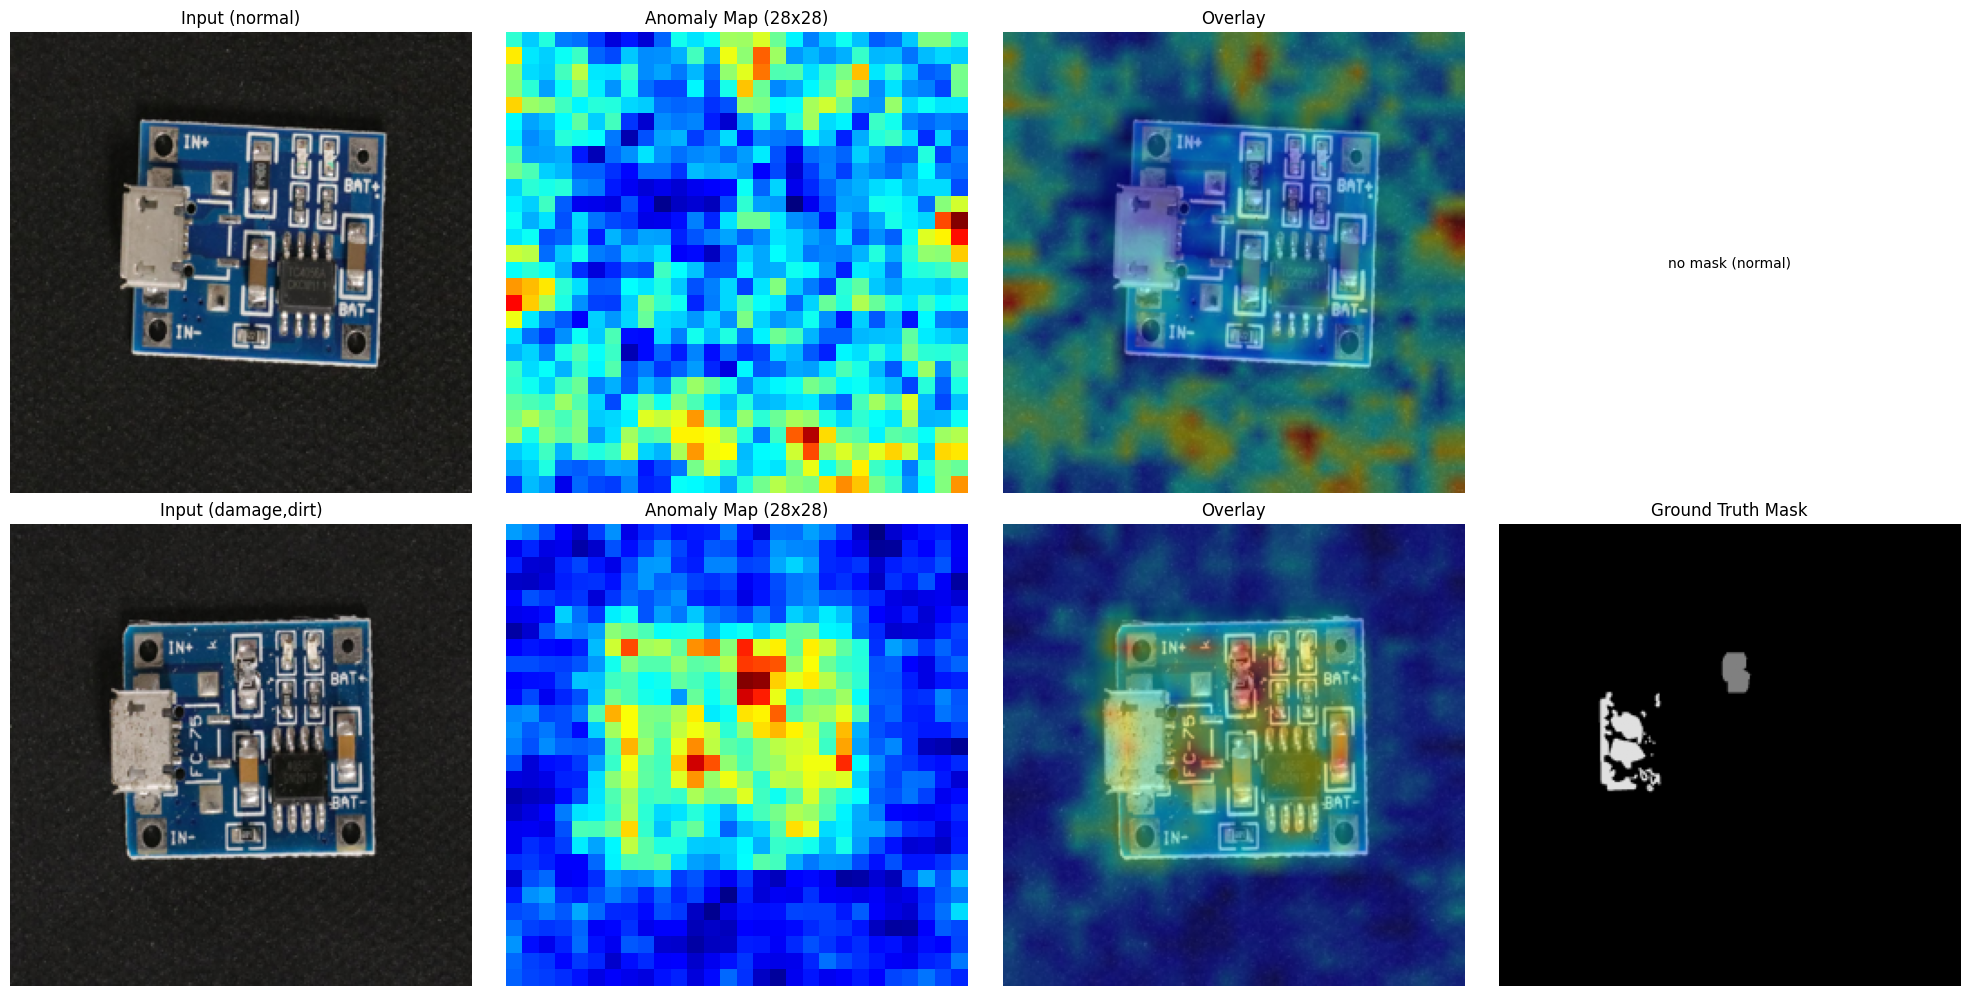

In [38]:
# (추가) Gradio 화면은 노트북에 안 남아서 같은 추론 함수에 직접 넣어보기
# 0번(정상), 210번(불량, 위에서 마스크 본 이미지)
import time

test_ds = test_loader.dataset  # 테스트셋 (정상 201 + 불량 100)
mask_ds = VisADataset(DATA_PATH, CATEGORY_NAME, is_train=False, include_mask=True)  # 정답 마스크 확인용

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for row, idx in enumerate([0, 210]):
    img = Image.open(test_ds.image_paths[idx]).convert('RGB')

    start = time.time()
    result_text, heatmap, overlay = padim_inference_gradio(img)
    elapsed = time.time() - start
    print(f"[{idx}번] 실제 라벨: {test_ds.defect_types[idx]} | {result_text.replace(chr(10), ' / ')} | 추론 시간: {elapsed:.3f}초")

    axes[row, 0].imshow(img.resize((IMG_SIZE, IMG_SIZE)))
    axes[row, 0].set_title(f"Input ({test_ds.defect_types[idx]})")
    axes[row, 1].imshow(heatmap)
    axes[row, 1].set_title('Anomaly Map (28x28)')
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title('Overlay')
    mask_path = mask_ds.mask_paths[idx]
    if mask_path is not None:
        axes[row, 3].imshow(Image.open(mask_path).convert('L').resize((IMG_SIZE, IMG_SIZE)), cmap='gray')
        axes[row, 3].set_title('Ground Truth Mask')
    else:
        axes[row, 3].text(0.5, 0.5, 'no mask (normal)', ha='center', va='center')
    for ax in axes[row]:
        ax.axis('off')
plt.tight_layout()
plt.show()

### 0번(정상) vs 210번(불량) 결과

| 이미지 | 실제 라벨 | 이상 점수 | 판정 (score > 15) | 걸린 시간 |
|---|---|---:|---|---:|
| 0번 | normal | 13.43 | 정상 | 0.267초 |
| 210번 | damage,dirt | 21.85 | 비정상 | 0.208초 |

210번 히트맵에서 제일 빨간 곳이 마스크 위쪽 작은 결함이랑 거의 겹친다. 왼쪽 커넥터 쪽 결함은 그보다 약하게 나왔다.

정상인 0번 히트맵에도 빨간 칸이 있는데, 이미지마다 자기 점수 범위에 맞춰서 색을 칠하기 때문이다. 색만 보고 판단하면 안 되고 점수를 같이 봐야 한다.

한 장에 0.2초쯤 걸렸다. 784개 위치를 for문으로 하나씩 계산하는 구조라 이 부분을 한 번에 계산하면 더 빨라질 것 같다.

In [39]:
# (추가) 판정 기준 score > 15가 실제 점수 범위랑 맞는지 테스트 301장으로 확인
all_scores, all_labels = [], []
for batch in tqdm(test_loader, desc='테스트셋 점수 계산'):
    scores, _ = gradio_padim_model.predict(batch['image'].to(device))
    all_scores.extend(scores)
    all_labels.extend(batch['label'].numpy())
all_scores, all_labels = np.array(all_scores), np.array(all_labels)

normal_scores, anomaly_scores = all_scores[all_labels == 0], all_scores[all_labels == 1]
print(f'layer1~3 PaDiM(실시간 추론용) AUROC: {roc_auc_score(all_labels, all_scores):.4f}')
print(f'정상 점수: 최소 {normal_scores.min():.2f} / 평균 {normal_scores.mean():.2f} / 최대 {normal_scores.max():.2f}')
print(f'불량 점수: 최소 {anomaly_scores.min():.2f} / 평균 {anomaly_scores.mean():.2f} / 최대 {anomaly_scores.max():.2f}')

# 테스트셋에서 F1 최대인 임계값 (테스트로 고른 거라 참고만)
precision, recall, thresholds = precision_recall_curve(all_labels, all_scores)
f1 = 2 * precision * recall / (precision + recall + 1e-8)
best_th = thresholds[np.argmax(f1[:-1])]

for th in [15, best_th]:
    pred = all_scores > th
    print(f'임계값 {th:.2f}: 정상 {len(normal_scores)}장 중 {pred[all_labels == 0].sum()}장을 불량으로 판정 / '
          f'불량 {len(anomaly_scores)}장 중 {pred[all_labels == 1].sum()}장 검출')

테스트셋 점수 계산: 100%|██████████| 38/38 [00:30<00:00,  1.24it/s]

layer1~3 PaDiM(실시간 추론용) AUROC: 0.9788
정상 점수: 최소 11.99 / 평균 17.57 / 최대 33.45
불량 점수: 최소 21.30 / 평균 31.84 / 최대 56.97
임계값 15.00: 정상 201장 중 135장을 불량으로 판정 / 불량 100장 중 100장 검출
임계값 23.18: 정상 201장 중 13장을 불량으로 판정 / 불량 100장 중 94장 검출


### 판정 기준 15가 맞는지 (테스트 301장)

실시간 추론용 모델(layer1+2+3)의 AUROC는 0.9788로 위 PaDiM(0.9668)보다 조금 높았다. 다만 layer1 추가, 좌우 반전 제거, 랜덤 투영이 한꺼번에 달라서 무엇 때문인지는 여기서는 알 수 없다(뒤 추가 분석 D에서 확인).

정상 점수는 평균 17.57(11.99 ~ 33.45), 불량은 평균 31.84(21.30 ~ 56.97)였다. 코드에 있는 기준 15를 쓰면 불량 100장은 다 잡지만 정상 201장 중 135장도 불량으로 나온다. 위에서 0번이 정상으로 나온 건 정상 중에서도 점수가 낮은 편이라서였다.

테스트셋에서 F1이 제일 높은 기준(23.18)을 쓰면 정상 13장을 잘못 잡고 불량 94장을 잡는다. 이것도 테스트셋 보고 고른 값이라 원래는 따로 떼어 둔 검증 데이터로 정해야 한다.

## 추가 분석

위에서는 강의 코드를 한 번 돌린 숫자를 그대로 적었는데 다시 보니 걸리는 게 있었다.

- 데이터를 CSV 앞 80% / 뒤 20%로 한 번만 나눴고, PaDiM 랜덤 투영(`torch.randn`)도 seed를 안 정해서 다시 돌리면 값이 바뀔 수 있다.
- 0.9668 → 0.9788은 레이어(2+3 → 1+2+3)랑 좌우 반전을 동시에 바꾼 거라 무엇 때문에 올랐는지 모른다.
- Best F1은 테스트셋에서 임계값을 고른 거라 부풀려져 있다.
- AE는 입력(-2.1 ~ 2.6)과 출력(0 ~ 1) 범위가 안 맞는 상태로 비교했다.

그래서 seed, 분할, 레이어와 좌우 반전을 하나씩 바꿔 가며 다시 돌려 봤다.

분할은 seed마다 정상을 학습 603 / 검증 201 / 테스트 201장, 불량을 검증 40 / 테스트 60장으로 나눴다. 학습엔 정상만 쓰고 검증셋은 임계값이랑 early stopping에만 썼다. B의 하이퍼파라미터는 강의 코드 값(PaDiM d=100, OCSVM nu=0.1, AE 50 epoch) 그대로 두고 테스트 결과를 보고 바꾸지 않았다. 좌우 반전 증강은 B, C에서는 빼고 D에서 따로 비교했다.

In [1]:
# 설정 + 데이터 준비 (새 런타임에서 이 아래만 돌려도 되게)
import os, time, tarfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from PIL import Image
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

QUICK = False  # True면 seed, epoch 줄여서 빠르게 테스트
SEEDS = [0, 1] if QUICK else [0, 1, 2, 3, 4]
AE_EPOCHS = 3 if QUICK else 50
N_BOOT = 300 if QUICK else 2000
DATA, CAT, IMG = './VisA', 'pcb4', 256
device = torch.device('cuda')
plt.rcParams['figure.dpi'] = 80

if not os.path.exists(f'{DATA}/{CAT}/image_anno.csv'):
    if not os.path.exists('VisA_20220922.tar'):
        !wget -q https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar
    with tarfile.open('VisA_20220922.tar') as tar:  # pcb4만 풀기
        members = [m for m in tar.getmembers() if m.name.lstrip('./').startswith(CAT + '/')]
        tar.extractall(DATA, members=members, filter='data')
print(torch.cuda.get_device_name(0), '| torch', torch.__version__)

Tesla T4 | torch 2.11.0+cu130



In [2]:
# pcb4 1,105장을 256x256으로 한 번만 읽어서 GPU에 올려둠
df = pd.read_csv(f'{DATA}/{CAT}/image_anno.csv')
paths = [f'{DATA}/{p}' if p.startswith(CAT + '/') else f'{DATA}/{CAT}/{p}' for p in df['image']]
labels = (df['label'] != 'normal').astype(int).values
t0 = time.time()
imgs = np.stack([np.asarray(Image.open(p).convert('RGB').resize((IMG, IMG), Image.BILINEAR)) for p in paths])
X_all = torch.from_numpy(imgs).permute(0, 3, 1, 2).contiguous().to(device)
del imgs
print(f'이미지 {len(paths)}장 (정상 {(labels == 0).sum()}, 불량 {(labels == 1).sum()}), {time.time() - t0:.0f}초')


def make_split(seed, n_val_anom=40):
    """정상: 테스트 201 / 검증 201 / 학습 603, 불량: 검증 40 / 테스트 60"""
    rng = np.random.RandomState(seed)
    nor = rng.permutation(np.where(labels == 0)[0])
    ano = rng.permutation(np.where(labels == 1)[0])
    return dict(train=nor[402:], val_n=nor[201:402], test_n=nor[:201],
                val_a=ano[:n_val_anom], test_a=ano[n_val_anom:])


def original_split():
    """위 실습이랑 같은 분할 (CSV 앞 80% 학습)"""
    nor, ano = np.where(labels == 0)[0], np.where(labels == 1)[0]
    k = int(len(nor) * 0.8)
    return dict(train=nor[:k], test_n=nor[k:], test_a=ano)


sp0 = make_split(0)
print({k: len(v) for k, v in sp0.items()})

이미지 1105장 (정상 1005, 불량 100), 25초
{'train': 603, 'val_n': 201, 'test_n': 201, 'val_a': 40, 'test_a': 60}



In [3]:
# 평가 지표 + 신뢰구간
def fast_auc(y, s):
    """AUROC (rank로 계산, 부트스트랩 빠르게 돌리려고)"""
    y = np.asarray(y); r = rankdata(s)
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def evaluate(s_valn, s_test_n, s_test_a):
    """임계값 = 검증 정상 점수의 95% 지점, 테스트에 그대로 적용"""
    y = np.r_[np.zeros(len(s_test_n)), np.ones(len(s_test_a))]
    s = np.r_[s_test_n, s_test_a]
    thr = np.percentile(s_valn, 95)
    pred = s > thr
    tp, fp = pred[y == 1].sum(), pred[y == 0].sum()
    prec, rec = tp / max(tp + fp, 1), tp / len(s_test_a)
    p, r, _ = precision_recall_curve(y, s)
    return dict(AUROC=fast_auc(y, s), AP=average_precision_score(y, s), Recall=rec, FPR=fp / len(s_test_n),
                F1_val_thr=2 * prec * rec / (prec + rec + 1e-12), F1_test_best=np.max(2 * p * r / (p + r + 1e-12)))


def _boot_idx(rng, y):
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    return np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]


def boot_ci(y, s, B=N_BOOT, seed=0):
    """부트스트랩 95% CI"""
    rng = np.random.RandomState(seed)
    v = [fast_auc(y[i], s[i]) for i in (_boot_idx(rng, y) for _ in range(B))]
    return np.percentile(v, [2.5, 97.5])


def paired_diff_ci(y, s1, s2, B=N_BOOT, seed=0):
    """같은 테스트 이미지로 두 방법 AUROC 차이 CI"""
    rng = np.random.RandomState(seed)
    d = []
    for _ in range(B):
        i = _boot_idx(rng, y)
        d.append(fast_auc(y[i], s1[i]) - fast_auc(y[i], s2[i]))
    return fast_auc(y, s1) - fast_auc(y, s2), np.percentile(d, [2.5, 97.5])


print(fast_auc([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8]), roc_auc_score([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8]))

0.75 0.75



In [4]:
# Wide ResNet-50 특징 미리 뽑아두기
# maps: layer1~3을 28x28로 (PaDiM용)
# gpool: 이미지 전체 평균 (OCSVM용)
backbone = models.wide_resnet50_2(weights='IMAGENET1K_V1').to(device).eval()  # pretrained=True랑 같은 가중치
LAYERS = ['layer1', 'layer2', 'layer3']
LAYER_CH = {'layer1': 256, 'layer2': 512, 'layer3': 1024}
_feats = {}
for _name in LAYERS:
    getattr(backbone, _name).register_forward_hook(lambda m, i, o, n=_name: _feats.__setitem__(n, o))
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


@torch.no_grad()
def extract(idx, flip=None, bs=32):
    maps = {l: [] for l in LAYERS}; gpool = []
    for i in range(0, len(idx), bs):
        x = X_all[torch.as_tensor(idx[i:i + bs], device=device)].float() / 255.
        if flip is not None:  # 학습 이미지 좌우 반전
            f = torch.as_tensor(flip[i:i + bs], device=device)
            x[f] = x[f].flip(-1)
        backbone((x - MEAN) / STD)
        for l in LAYERS:
            maps[l].append(F.adaptive_avg_pool2d(_feats[l], (28, 28)).half())
        gpool.append(torch.cat([_feats[l].mean((2, 3)) for l in LAYERS], 1).float().cpu())
    return {l: torch.cat(v) for l, v in maps.items()}, torch.cat(gpool).numpy()


t0 = time.time()
MAPS, GPOOL = extract(np.arange(len(labels)))
print({l: tuple(v.shape) for l, v in MAPS.items()}, GPOOL.shape, f'{time.time() - t0:.0f}초',
      f'| GPU 메모리 {torch.cuda.memory_allocated() / 1e9:.1f}GB')

{'layer1': (1105, 256, 28, 28), 'layer2': (1105, 512, 28, 28), 'layer3': (1105, 1024, 28, 28)} (1105, 1792) 8초 | GPU 메모리 3.7GB



In [5]:
# PaDiM / OCSVM / AE 다시 구현 (점수 계산은 위랑 같고 반복 실험하려고 한 번에 계산하게 바꿈. AE는 val loss로 early stopping 추가)
def _rows(r):
    return torch.as_tensor(np.asarray(r), device=device)


def project(maps, rows, layers, P, bs=64):
    """위치별 특징 랜덤 투영 -> [n, 784, d] (레이어별로 투영해서 더함)"""
    out = []
    for i in range(0, len(rows), bs):
        r = _rows(rows[i:i + bs]); z = 0; c0 = 0
        for l in layers:
            C = LAYER_CH[l]
            z = z + maps[l][r].float().flatten(2).transpose(1, 2) @ P[c0:c0 + C]
            c0 += C
        out.append(z)
    return torch.cat(out)


def padim_fit(maps, rows, layers=('layer2', 'layer3'), d=100, seed=0):
    """위치마다 평균, 공분산(+1e-4 I)"""
    g = torch.Generator(device=device).manual_seed(seed)
    P = F.normalize(torch.randn(sum(LAYER_CH[l] for l in layers), d, generator=g, device=device), dim=0)
    Z = project(maps, rows, layers, P)
    mu = Z.mean(0); Zc = Z - mu
    cov = torch.einsum('npd,npe->pde', Zc, Zc) / (len(rows) - 1) + 1e-4 * torch.eye(d, device=device)
    # GPU에서 inv를 한 번에 하니까 T4에서 illegal memory access 에러 -> CPU로 계산
    inv = torch.linalg.inv(cov.double().cpu()).float().to(device)
    return dict(P=P, mu=mu, inv=inv, layers=list(layers))


def padim_score(model, maps, rows, bs=64):
    """이미지 점수 = 784개 위치 마할라노비스 거리 중 최댓값"""
    out = []
    for i in range(0, len(rows), bs):
        z = project(maps, rows[i:i + bs], model['layers'], model['P']) - model['mu']
        m = torch.einsum('npd,pde,npe->np', z, model['inv'], z)
        out.append(m.clamp_min(0).sqrt().max(1).values)
    return torch.cat(out).cpu().numpy()


OC_COLS = slice(256, 256 + 512 + 1024)  # layer2+3 평균 특징 (위 OCSVM이랑 같음)


def ocsvm_fit(train_feat, nu=0.1, gamma='scale'):
    sc = StandardScaler().fit(train_feat)
    svm = OneClassSVM(nu=nu, kernel='rbf', gamma=gamma).fit(sc.transform(train_feat))
    return lambda f: -svm.decision_function(sc.transform(f))  # 클수록 이상


class ConvAE(nn.Module):
    """위 ConvAutoEncoder랑 같은 구조"""
    def __init__(self, c=3, latent=128):
        super().__init__()
        ch = [c, 32, 64, 128, 256, latent]
        enc = []
        for a, b in zip(ch[:-1], ch[1:]):
            enc += [nn.Conv2d(a, b, 4, 2, 1), nn.BatchNorm2d(b), nn.ReLU()]
        dec = []
        rch = [latent, 256, 128, 64, 32]
        for a, b in zip(rch[:-1], rch[1:]):
            dec += [nn.ConvTranspose2d(a, b, 4, 2, 1), nn.BatchNorm2d(b), nn.ReLU()]
        dec += [nn.ConvTranspose2d(32, c, 4, 2, 1), nn.Sigmoid()]
        self.encoder, self.decoder = nn.Sequential(*enc), nn.Sequential(*dec)

    def forward(self, x):
        return self.decoder(self.encoder(x))


def ae_input(rows, normalize):
    x = X_all[_rows(rows)].float() / 255.
    return (x - MEAN) / STD if normalize else x  # normalize=True가 원래 입력


@torch.no_grad()
def ae_scores(model, rows, normalize, bs=64):
    model.eval(); out = []
    for i in range(0, len(rows), bs):
        x = ae_input(rows[i:i + bs], normalize)
        out.append(((model(x) - x) ** 2).flatten(1).mean(1))
    return torch.cat(out).cpu().numpy()


def ae_train(sp, normalize, seed, epochs=AE_EPOCHS, bs=16):
    """Adam 1e-3, batch 16, MSE (위랑 같음). epoch마다 train/val loss, 검증 AUROC 기록
    val loss 제일 낮았던 epoch로 되돌림 (early stopping)"""
    torch.manual_seed(seed)
    model = ConvAE().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    yv = np.r_[np.zeros(len(sp['val_n'])), np.ones(len(sp['val_a']))]
    tr_probe = sp['train'][:201]  # train loss도 eval 모드로 다시 재려고 201장
    xvar = ae_input(sp['train'][:201], normalize).var().item()  # 입력 분산 (두 AE loss 크기 맞춰서 보려고)
    hist = dict(train_step=[], train=[], val=[], val_auroc=[], xvar=xvar)
    g = torch.Generator().manual_seed(seed)
    best = (np.inf, None, -1)
    for ep in range(epochs):
        model.train(); tot = 0
        perm = sp['train'][torch.randperm(len(sp['train']), generator=g).numpy()]
        for i in range(0, len(perm), bs):
            x = ae_input(perm[i:i + bs], normalize)
            loss = F.mse_loss(model(x), x)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(x)
        hist['train_step'].append(tot / len(perm))
        hist['train'].append(ae_scores(model, tr_probe, normalize).mean())
        s_vn, s_va = ae_scores(model, sp['val_n'], normalize), ae_scores(model, sp['val_a'], normalize)
        hist['val'].append(s_vn.mean())
        hist['val_auroc'].append(fast_auc(yv, np.r_[s_vn, s_va]))
        if hist['val'][-1] < best[0]:
            best = (hist['val'][-1], {k: v.detach().clone() for k, v in model.state_dict().items()}, ep)
    model.load_state_dict(best[1])
    return model, hist, best[2]


print('함수 준비 완료')

함수 준비 완료



### A. 같은 분할에서 다시 돌려도 같은 값이 나올까

데이터는 위랑 똑같이 두고 PaDiM 랜덤 투영 행렬이랑 좌우 반전 seed만 바꿔서 5번 돌려봤다.

      비교 실험 PaDiM (layer2+3, 반전 O)  실시간 PaDiM (layer1+2+3, 반전 X)
seed                                                            
0                           0.9500                        0.9765
1                           0.9619                        0.9820
2                           0.9564                        0.9813
3                           0.9546                        0.9739
4                           0.9574                        0.9777

평균 / 표준편차 / 최소 / 최대
      비교 실험 PaDiM (layer2+3, 반전 O)  실시간 PaDiM (layer1+2+3, 반전 X)
mean                        0.9561                        0.9783
std                         0.0043                        0.0034
min                         0.9500                        0.9739
max                         0.9619                        0.9820

위 실습에서 적은 값: 비교 실험 PaDiM 0.9668, 실시간 PaDiM 0.9788

seed 0 비교 실험 PaDiM AUROC 0.9500, 부트스트랩 95% 신뢰구간 [0.9236, 0.9696]

두 설정의 차이(실시간 - 비교 실험), 같은 테스트 이미지로 계산한 95% 신뢰구간:
  seed 0: 차이 +0.0264, 95% CI [+0

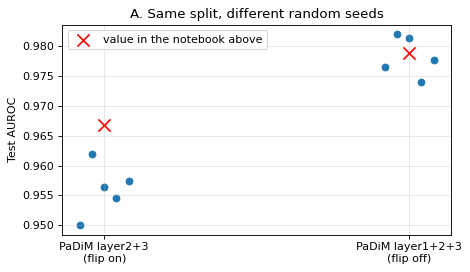

In [6]:
# A. 원래 분할에서 seed만 바꿔서 5번
osp = original_split()
te_rows = np.r_[osp['test_n'], osp['test_a']]
y_te = np.r_[np.zeros(len(osp['test_n'])), np.ones(len(osp['test_a']))]
resA, scoresA = [], {}
for seed in SEEDS:
    flip = np.random.RandomState(seed).rand(len(osp['train'])) < 0.5  # 절반 정도 좌우 반전
    fmaps, _ = extract(osp['train'], flip=flip)
    m = padim_fit(fmaps, np.arange(len(osp['train'])), ['layer2', 'layer3'], 100, seed)
    s_cmp = padim_score(m, MAPS, te_rows)
    del fmaps, m; torch.cuda.empty_cache()
    m = padim_fit(MAPS, osp['train'], ['layer1', 'layer2', 'layer3'], 100, seed)
    s_rt = padim_score(m, MAPS, te_rows)
    scoresA[seed] = (s_cmp, s_rt)
    resA.append(dict(seed=seed, cmp=fast_auc(y_te, s_cmp), realtime=fast_auc(y_te, s_rt)))
dfA = pd.DataFrame(resA).set_index('seed')
dfA.columns = ['비교 실험 PaDiM (layer2+3, 반전 O)', '실시간 PaDiM (layer1+2+3, 반전 X)']
print(dfA.round(4).to_string())
print('\n평균 / 표준편차 / 최소 / 최대')
print(dfA.agg(['mean', 'std', 'min', 'max']).round(4).to_string())
print('\n위 실습에서 적은 값: 비교 실험 PaDiM 0.9668, 실시간 PaDiM 0.9788')
lo, hi = boot_ci(y_te, scoresA[SEEDS[0]][0])
print(f'\nseed {SEEDS[0]} 비교 실험 PaDiM AUROC {dfA.iloc[0, 0]:.4f}, 부트스트랩 95% 신뢰구간 [{lo:.4f}, {hi:.4f}]')
print('\n두 설정의 차이(실시간 - 비교 실험), 같은 테스트 이미지로 계산한 95% 신뢰구간:')
for seed in SEEDS:
    d, (lo, hi) = paired_diff_ci(y_te, scoresA[seed][1], scoresA[seed][0])
    print(f'  seed {seed}: 차이 {d:+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}] -> {"0을 포함(차이가 있다고 보기 어려움)" if lo <= 0 <= hi else "0을 포함하지 않음"}')

fig, ax = plt.subplots(figsize=(6, 3.5))
for j, (col, rep) in enumerate(zip(dfA.columns, [0.9668, 0.9788])):
    ax.scatter(np.full(len(dfA), j) + np.linspace(-0.08, 0.08, len(dfA)), dfA[col], label=None, color='C0')
    ax.scatter(j, rep, marker='x', s=120, color='red', label='value in the notebook above' if j == 0 else None)
ax.set_xticks([0, 1]); ax.set_xticklabels(['PaDiM layer2+3\n(flip on)', 'PaDiM layer1+2+3\n(flip off)'])
ax.set_ylabel('Test AUROC'); ax.set_title('A. Same split, different random seeds'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

| | 원래 분할, seed 5개 | 위에서 적은 값 |
|---|---:|---:|
| PaDiM layer2+3, 반전 O | 0.9561 ± 0.0043 (0.9500 ~ 0.9619) | 0.9668 |
| PaDiM layer1+2+3, 반전 X | 0.9783 ± 0.0034 (0.9739 ~ 0.9820) | 0.9788 |

그래프에서 파란 점이 seed별 결과, 빨간 X가 위에서 적은 값이다. 오른쪽은 X가 점들 사이에 있는데 왼쪽은 X가 점들보다 위에 혼자 떨어져 있다.

seed만 바꿔도 AUROC가 0.01 정도 오르내린다. 0.9668은 5번 중 최댓값(0.9619)보다도 높고, 평균(0.9561)보다 표준편차의 2.5배쯤 위라 seed 차이만으로는 설명하기 어렵다. float16으로 저장해서 그런가 싶어 E-2에서 float32로 다시 해봤는데 값이 똑같았다. 원래 돌린 seed를 모르고, 다시 짠 코드가 강의 코드랑 완전히 같은 값을 내는지도 맞춰 보지 못해서 구현 차이일 가능성도 남는다.

seed 0 기준 부트스트랩 95% 신뢰구간이 [0.924, 0.970]으로 폭이 0.05쯤 된다. 테스트 불량이 100장뿐이라 테스트 이미지가 바뀌면 0.01 정도는 쉽게 움직인다. 그래도 두 설정 차이(+0.019 ~ +0.026)는 5번 다 신뢰구간이 0을 안 걸쳐서 우연으로 보기는 어렵다. 원인은 D에서 봤다.

### B. 같은 조건에서 4가지 방법 비교 (분할 5개, 테스트셋)

B는 네 방법 모두 좌우 반전 없이 학습했다. PaDiM은 D의 layer2+3 설정이랑 같다. AE는 강의 코드 구조 그대로인 AE(original)이랑 입력만 0 ~ 1로 바꾼 AE(fixed) 두 개를 넣었다. 구조, lr, epoch는 같고, 둘 다 val loss로 early stopping을 했다.

- AUROC, AP: 임계값 없이 정상/불량을 얼마나 잘 나누는지
- Recall, FPR, F1_val_thr: 검증 정상 점수의 95% 지점을 임계값으로 잡고 테스트에 그대로 적용했을 때
- F1_test_best: 위에서처럼 테스트셋에서 최적 임계값을 고른 F1 (비교용)

In [7]:
# B. 분할 5개 x 방법 4개
METHODS = ['PaDiM', 'OCSVM', 'AE(original)', 'AE(fixed)']
resB, scoresB, ae_hist = [], {}, {}
t0 = time.time()
for seed in SEEDS:
    sp = make_split(seed)
    keys = ['val_n', 'test_n', 'test_a']
    sc = {}
    m = padim_fit(MAPS, sp['train'], ['layer2', 'layer3'], 100, seed)
    sc['PaDiM'] = [padim_score(m, MAPS, sp[k]) for k in keys]
    f = ocsvm_fit(GPOOL[sp['train']][:, OC_COLS])
    sc['OCSVM'] = [f(GPOOL[sp[k]][:, OC_COLS]) for k in keys]
    for name, norm in [('AE(original)', True), ('AE(fixed)', False)]:
        model, hist, best_ep = ae_train(sp, norm, seed)
        ae_hist[(name, seed)] = (hist, best_ep)
        sc[name] = [ae_scores(model, sp[k], norm) for k in keys]
        del model; torch.cuda.empty_cache()
    yt = np.r_[np.zeros(len(sp['test_n'])), np.ones(len(sp['test_a']))]
    scoresB[seed] = (yt, {k: np.r_[v[1], v[2]] for k, v in sc.items()})
    for name in METHODS:
        r = evaluate(*sc[name]); r.update(seed=seed, method=name); resB.append(r)
    print(f'seed {seed} 완료 ({time.time() - t0:.0f}초):', {k: round(fast_auc(yt, s), 4) for k, s in scoresB[seed][1].items()})

dfB = pd.DataFrame(resB)
cols = ['AUROC', 'AP', 'Recall', 'FPR', 'F1_val_thr', 'F1_test_best']
g = dfB.groupby('method')[cols]
tableB = (g.mean().round(3).astype(str) + ' ± ' + g.std().round(3).astype(str)).loc[METHODS]
print('\n[테스트셋, 분할 5개 평균 ± 표준편차]')
print(tableB.to_string())

seed 0 완료 (239초): {'PaDiM': np.float64(0.9726), 'OCSVM': np.float64(0.9054), 'AE(original)': np.float64(0.7186), 'AE(fixed)': np.float64(0.9686)}
seed 1 완료 (477초): {'PaDiM': np.float64(0.9769), 'OCSVM': np.float64(0.9167), 'AE(original)': np.float64(0.7307), 'AE(fixed)': np.float64(0.9667)}
seed 2 완료 (717초): {'PaDiM': np.float64(0.9696), 'OCSVM': np.float64(0.8765), 'AE(original)': np.float64(0.7444), 'AE(fixed)': np.float64(0.9763)}
seed 3 완료 (955초): {'PaDiM': np.float64(0.9758), 'OCSVM': np.float64(0.8798), 'AE(original)': np.float64(0.7525), 'AE(fixed)': np.float64(0.9493)}
seed 4 완료 (1193초): {'PaDiM': np.float64(0.9723), 'OCSVM': np.float64(0.9329), 'AE(original)': np.float64(0.7769), 'AE(fixed)': np.float64(0.9544)}

[테스트셋, 분할 5개 평균 ± 표준편차]
                      AUROC             AP         Recall            FPR     F1_val_thr   F1_test_best
method                                                                                                
PaDiM         0.973 ± 0.003  0.891 ± 0

[방법별 AUROC와 95% 신뢰구간 (분할별)]
                       PaDiM                 OCSVM          AE(original)             AE(fixed)
seed 0  0.973 [0.952, 0.989]  0.905 [0.861, 0.942]  0.719 [0.656, 0.777]  0.969 [0.950, 0.985]
seed 1  0.977 [0.960, 0.991]  0.917 [0.875, 0.952]  0.731 [0.668, 0.789]  0.967 [0.948, 0.983]
seed 2  0.970 [0.950, 0.985]  0.877 [0.828, 0.916]  0.744 [0.686, 0.800]  0.976 [0.957, 0.992]
seed 3  0.976 [0.958, 0.990]  0.880 [0.835, 0.921]  0.752 [0.691, 0.808]  0.949 [0.923, 0.971]
seed 4  0.972 [0.954, 0.987]  0.933 [0.903, 0.960]  0.777 [0.717, 0.834]  0.954 [0.929, 0.977]

[AUROC 차이 (앞 - 뒤)와 95% 신뢰구간]
                      비교                  seed 0                  seed 1                  seed 2                  seed 3                  seed 4 CI가 0을 안 포함한 분할 수
           PaDiM - OCSVM +0.067 [+0.028, +0.112] +0.060 [+0.024, +0.101] +0.093 [+0.053, +0.140] +0.096 [+0.056, +0.140] +0.039 [+0.012, +0.071]               5/5
       PaDiM - AE(fixed) +0.004 [-0.017, +0.02

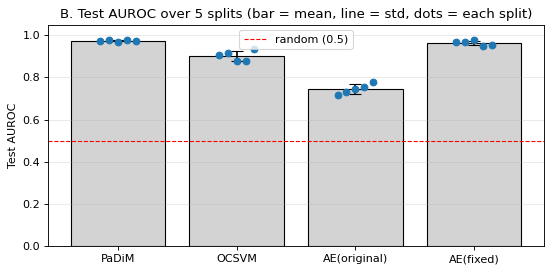

In [8]:
# B. 신뢰구간 (방법별 AUROC CI, 두 방법 차이 CI)
print('[방법별 AUROC와 95% 신뢰구간 (분할별)]')
rows = []
for seed in SEEDS:
    yt, S = scoresB[seed]
    row = {}
    for m in METHODS:
        lo, hi = boot_ci(yt, S[m])
        row[m] = f'{fast_auc(yt, S[m]):.3f} [{lo:.3f}, {hi:.3f}]'
    rows.append(row)
print(pd.DataFrame(rows, index=[f'seed {s}' for s in SEEDS]).to_string())

PAIRS = [('PaDiM', 'OCSVM'), ('PaDiM', 'AE(fixed)'), ('OCSVM', 'AE(fixed)'), ('AE(fixed)', 'AE(original)')]
print('\n[AUROC 차이 (앞 - 뒤)와 95% 신뢰구간]')
pair_rows = []
for a, b in PAIRS:
    cnt = 0; txt = []
    for seed in SEEDS:
        yt, S = scoresB[seed]
        d, (lo, hi) = paired_diff_ci(yt, S[a], S[b])
        cnt += int(lo > 0 or hi < 0)
        txt.append(f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}]')
    pair_rows.append([f'{a} - {b}'] + txt + [f'{cnt}/{len(SEEDS)}'])
print(pd.DataFrame(pair_rows, columns=['비교'] + [f'seed {s}' for s in SEEDS] + ['CI가 0을 안 포함한 분할 수']).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.5))
for j, m in enumerate(METHODS):
    v = dfB[dfB.method == m].AUROC.values
    ax.bar(j, v.mean(), color='lightgray', edgecolor='k')
    ax.errorbar(j, v.mean(), yerr=v.std(ddof=1) if len(v) > 1 else 0, color='k', capsize=5)
    ax.scatter(np.full(len(v), j) + np.linspace(-0.15, 0.15, len(v)), v, color='C0', zorder=3)
ax.axhline(0.5, ls='--', color='r', lw=1, label='random (0.5)')
ax.set_xticks(range(len(METHODS))); ax.set_xticklabels(METHODS); ax.set_ylabel('Test AUROC'); ax.set_ylim(0, 1.05)
ax.set_title('B. Test AUROC over 5 splits (bar = mean, line = std, dots = each split)'); ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

테스트 정상 201 / 불량 60, 분할 5개 평균 ± 표준편차

| 방법 | AUROC | AP | Recall | FPR | F1 (검증 임계값) | F1 (테스트 최적) |
|---|---:|---:|---:|---:|---:|---:|
| PaDiM | 0.973 ± 0.003 | 0.891 ± 0.025 | 0.867 ± 0.092 | 0.072 ± 0.049 | 0.824 ± 0.040 | 0.866 ± 0.017 |
| OCSVM | 0.902 ± 0.024 | 0.722 ± 0.086 | 0.580 ± 0.051 | 0.072 ± 0.015 | 0.637 ± 0.050 | 0.704 ± 0.038 |
| AE(original) | 0.745 ± 0.022 | 0.355 ± 0.026 | 0.010 ± 0.015 | 0.057 ± 0.026 | 0.016 ± 0.023 | 0.545 ± 0.010 |
| AE(fixed) | 0.963 ± 0.011 | 0.831 ± 0.063 | 0.807 ± 0.093 | 0.067 ± 0.038 | 0.794 ± 0.028 | 0.846 ± 0.028 |

| 비교 | AUROC 차이 (분할별) | 신뢰구간이 0을 안 걸친 분할 |
|---|---|---:|
| PaDiM - OCSVM | +0.039 ~ +0.096 | 5 / 5 |
| PaDiM - AE(fixed) | -0.007 ~ +0.027 | 1 / 5 |
| OCSVM - AE(fixed) | -0.100 ~ -0.021 | 4 / 5 |
| AE(fixed) - AE(original) | +0.178 ~ +0.250 | 5 / 5 |

막대그래프를 보면 PaDiM ≥ AE(fixed) > OCSVM ≫ AE(original) 순이다. 점(분할별 값)을 보면 PaDiM은 5개가 거의 한 줄로 모여 있고 OCSVM이랑 AE(original)이 넓게 퍼져 있다.

다만 PaDiM이랑 AE(fixed)는 5개 중 1개 분할에서만 차이가 났다. 이 데이터로는 PaDiM이 AE보다 낫다고 하기 어렵다.

같은 분할에서 입력 범위만 고치니 AE가 0.745 → 0.963이 됐다. 원래 분할에서 0.266이던 AE(original)도 랜덤 분할에서는 0.745라서 원래 분할 자체에도 뭔가 있는 것 같았다(E-1에서 확인).

테스트셋에서 고른 F1이 검증셋 기준 F1보다 0.04 ~ 0.07 높았다(AE(original) 빼고, PaDiM 0.866 vs 0.824). 위에 적은 Best F1 0.9005도 실제로는 더 낮을 거다. AE(original)은 검증 임계값으로는 불량을 1%밖에 못 잡았다.

오탐을 5%로 맞추려고 정한 임계값인데 테스트에서는 5.7 ~ 7.2%가 나왔고 PaDiM Recall도 분할마다 표준편차가 0.09나 된다. 검증 정상 201장으로 정한 임계값은 꽤 흔들린다.

### C. 과소적합 / 과적합

내가 이해하기로 과적합이랑 과소적합은 결국 학습에 쓴 데이터에서 성능과 처음 보는 데이터에서 성능이 얼마나 다르냐다. 둘 다 안 좋으면 덜 배운 거(과소적합)고, 학습 데이터에서만 좋으면 외운 거(과적합)다.

AE는 경사하강법으로 학습하니까 epoch별 train/val loss를 보면 된다. 그런데 PaDiM이랑 OCSVM은 경사하강법을 안 써서 loss 곡선이 없다. 그래서 학습 데이터 양이나 모델 복잡도(PaDiM의 d, OCSVM의 gamma)를 바꿔 가면서 "학습에 쓴 정상 이미지" 점수랑 "처음 보는 정상 이미지" 점수가 얼마나 벌어지는지 봤다. 둘 다 정상인데 처음 보는 쪽만 점수가 훨씬 높으면 정상을 배운 게 아니라 학습 이미지를 외운 거다. C는 전부 검증셋 기준이다.

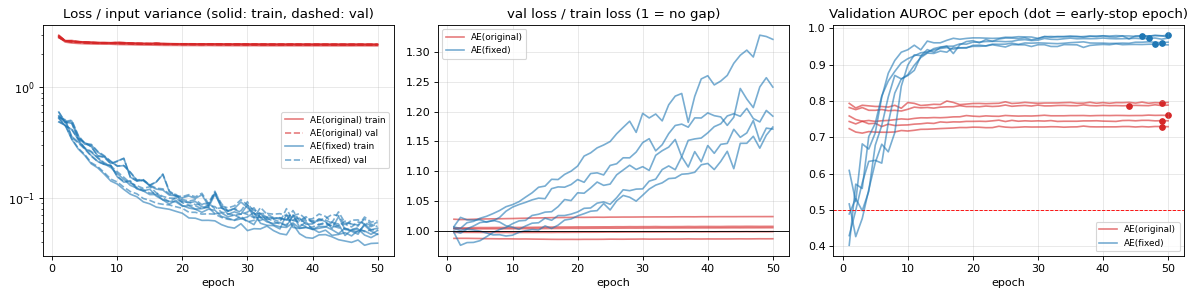

              best_epoch  train_loss_ratio  val_loss_ratio     gap  val_AUROC_ep1  val_AUROC_best  val_AUROC_max
method                                                                                                          
AE(fixed)           48.0            0.0443          0.0543  1.2299         0.4894          0.9700         0.9713
AE(original)        48.2            2.4288          2.4380  1.0040         0.7605          0.7637         0.7659



In [22]:
# C-1. AE train / val loss
# loss 크기가 입력 범위마다 달라서 입력 분산으로 나눠서 그림 (1이면 거의 복원 못 한 것)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for name, c in [('AE(original)', 'C3'), ('AE(fixed)', 'C0')]:
    for seed in SEEDS:
        h, best_ep = ae_hist[(name, seed)]
        ep = np.arange(1, len(h['train']) + 1)
        lab = name if seed == SEEDS[0] else None
        axes[0].plot(ep, np.array(h['train']) / h['xvar'], color=c, alpha=0.6, label=lab and f'{lab} train')
        axes[0].plot(ep, np.array(h['val']) / h['xvar'], color=c, ls='--', alpha=0.6, label=lab and f'{lab} val')
        axes[1].plot(ep, np.array(h['val']) / np.array(h['train']), color=c, alpha=0.6, label=lab)
        axes[2].plot(ep, h['val_auroc'], color=c, alpha=0.6, label=lab)
        axes[2].scatter(best_ep + 1, h['val_auroc'][best_ep], color=c, marker='o', s=25)
axes[0].set_title('Loss / input variance (solid: train, dashed: val)'); axes[0].set_yscale('log')
axes[1].set_title('val loss / train loss (1 = no gap)'); axes[1].axhline(1, color='k', lw=0.8)
axes[2].set_title('Validation AUROC per epoch (dot = early-stop epoch)'); axes[2].axhline(0.5, color='r', ls='--', lw=0.8)
for a in axes:
    a.set_xlabel('epoch'); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for name in ['AE(original)', 'AE(fixed)']:
    for seed in SEEDS:
        h, best_ep = ae_hist[(name, seed)]
        rows.append(dict(method=name, seed=seed, best_epoch=best_ep + 1,
                         train_loss_ratio=h['train'][best_ep] / h['xvar'], val_loss_ratio=h['val'][best_ep] / h['xvar'],
                         gap=h['val'][best_ep] / h['train'][best_ep], val_AUROC_best=h['val_auroc'][best_ep],
                         val_AUROC_ep1=h['val_auroc'][0], val_AUROC_max=max(h['val_auroc'])))
dfC1 = pd.DataFrame(rows)
print(dfC1.groupby('method')[['best_epoch', 'train_loss_ratio', 'val_loss_ratio', 'gap', 'val_AUROC_ep1', 'val_AUROC_best', 'val_AUROC_max']].mean().round(4).to_string())

loss는 입력 분산으로 나눈 값, 분할 5개 평균

| | train loss | val loss | val / train | 검증 AUROC (1 epoch → early stopping epoch) | val loss 최저 epoch |
|---|---:|---:|---:|---|---:|
| AE(original) | 2.43 | 2.44 | 1.00 | 0.761 → 0.764 | 48 / 50 |
| AE(fixed) | 0.044 | 0.054 | 1.23 | 0.489 → 0.970 | 48 / 50 |

왼쪽 그래프에서 빨간 선(AE original)은 2.4 근처에서 처음부터 거의 평평하고, 파란 선(AE fixed)은 0.5에서 0.05 근처까지 내려간다. 오른쪽 검증 AUROC도 AE(fixed)는 10 epoch쯤 0.9를 넘는데 AE(original)은 0.73 ~ 0.80에서 그대로다.

AE(original)은 과소적합이다. 복원 오차가 입력 분산의 2.4배라서 그냥 평균값 하나로 채우는 것보다도 못하다. train이랑 val이 같아서 외운 것도 아니고 50 epoch 동안 검증 AUROC도 거의 안 변했다.

AE(fixed)는 입력 분산의 95% 정도를 복원했다. 가운데 그래프를 보면 val/train 비율이 epoch가 갈수록 1.0에서 1.2 ~ 1.3까지 조금씩 벌어진다. 학습 이미지를 외우기 시작하는 조짐은 있는데, val loss 자체는 48 epoch까지 계속 내려가서 아직 과적합까지는 아니다. 50 epoch가 오히려 조금 모자랐던 것 같다.

In [23]:
# C-2. PaDiM 학습 이미지 수 25 ~ 603장 (d=100)
SIZES = [25, 50, 100, 200, 400, 603]
rows = []
for seed in SEEDS:
    sp = make_split(seed)
    yv = np.r_[np.zeros(len(sp['val_n'])), np.ones(len(sp['val_a']))]
    perm = np.random.RandomState(100 + seed).permutation(sp['train'])
    for n in SIZES:
        tr = perm[:n]
        m = padim_fit(MAPS, tr, ['layer2', 'layer3'], 100, seed)
        s_tr, s_vn, s_va = padim_score(m, MAPS, tr[:200]), padim_score(m, MAPS, sp['val_n']), padim_score(m, MAPS, sp['val_a'])
        rows.append(dict(seed=seed, n=n, val_AUROC=fast_auc(yv, np.r_[s_vn, s_va]), train_normal=np.median(s_tr),
                         val_normal=np.median(s_vn), val_anomaly=np.median(s_va)))
dfC2 = pd.DataFrame(rows)
sumC2 = dfC2.groupby('n')[['val_AUROC', 'train_normal', 'val_normal', 'val_anomaly']].mean()
sumC2['val_AUROC_std'] = dfC2.groupby('n')['val_AUROC'].std()
sumC2['gap(val/train)'] = sumC2['val_normal'] / sumC2['train_normal']
print('[점수는 중앙값, 분할 5개 평균]')
print(sumC2.round(3).to_string())

[점수는 중앙값, 분할 5개 평균]
     val_AUROC  train_normal  val_normal  val_anomaly  val_AUROC_std  gap(val/train)
n                                                                                   
25       0.972         4.781   57.462002    96.669998          0.014          12.020
50       0.972         6.831   42.227001    76.204002          0.011           6.182
100      0.976         9.283   27.072001    51.960999          0.008           2.916
200      0.976        11.360   19.260000    38.002998          0.011           1.695
400      0.977        12.728   16.532000    32.863998          0.009           1.299
603      0.977        13.243   15.711000    31.204000          0.009           1.186



In [24]:
# C-3. PaDiM 차원 d 바꾸기 (603장)
DIMS = [10, 25, 50, 100, 200, 400]
rows = []
for seed in SEEDS:
    sp = make_split(seed)
    yv = np.r_[np.zeros(len(sp['val_n'])), np.ones(len(sp['val_a']))]
    for d in DIMS:
        m = padim_fit(MAPS, sp['train'], ['layer2', 'layer3'], d, seed)
        s_tr, s_vn, s_va = padim_score(m, MAPS, sp['train'][:200]), padim_score(m, MAPS, sp['val_n']), padim_score(m, MAPS, sp['val_a'])
        rows.append(dict(seed=seed, d=d, val_AUROC=fast_auc(yv, np.r_[s_vn, s_va]), train_normal=np.median(s_tr),
                         val_normal=np.median(s_vn), val_anomaly=np.median(s_va)))
        del m; torch.cuda.empty_cache()
dfC3 = pd.DataFrame(rows)
sumC3 = dfC3.groupby('d')[['val_AUROC', 'train_normal', 'val_normal', 'val_anomaly']].mean()
sumC3['val_AUROC_std'] = dfC3.groupby('d')['val_AUROC'].std()
sumC3['gap(val/train)'] = sumC3['val_normal'] / sumC3['train_normal']
print('[점수는 중앙값, 분할 5개 평균]')
print(sumC3.round(3).to_string())

[점수는 중앙값, 분할 5개 평균]
     val_AUROC  train_normal  val_normal  val_anomaly  val_AUROC_std  gap(val/train)
d                                                                                   
10       0.929      5.597000    5.746000     8.537000          0.020           1.027
25       0.967      7.705000    8.117000    13.222000          0.010           1.054
50       0.973     10.093000   11.108000    20.355000          0.010           1.101
100      0.977     13.247000   15.711000    31.204000          0.009           1.186
200      0.981     16.945999   23.212000    50.117001          0.008           1.370
400      0.981     20.186001   35.234001    81.532997          0.008           1.745



In [25]:
# C-4. OCSVM gamma 바꾸기 (nu=0.1)
# gamma='scale'이 표준화 특징에서 1/1536이라 그 0.01배 ~ 100배로
MULTS = [0.01, 0.1, 1, 10, 100]
rows = []
for seed in SEEDS:
    sp = make_split(seed)
    yv = np.r_[np.zeros(len(sp['val_n'])), np.ones(len(sp['val_a']))]
    Ftr = GPOOL[sp['train']][:, OC_COLS]
    sc = StandardScaler().fit(Ftr); base = 1.0 / (Ftr.shape[1] * sc.transform(Ftr).var())
    for mult in MULTS:
        svm = OneClassSVM(nu=0.1, kernel='rbf', gamma=base * mult).fit(sc.transform(Ftr))
        dec = lambda k: svm.decision_function(sc.transform(GPOOL[sp[k]][:, OC_COLS]))
        d_tr, d_vn, d_va = svm.decision_function(sc.transform(Ftr)), dec('val_n'), dec('val_a')
        rows.append(dict(seed=seed, gamma_mult=mult, val_AUROC=fast_auc(yv, -np.r_[d_vn, d_va]),
                         train_normal_reject=(d_tr < 0).mean(), val_normal_reject=(d_vn < 0).mean(), val_anomaly_detect=(d_va < 0).mean()))
dfC4 = pd.DataFrame(rows)
sumC4 = dfC4.groupby('gamma_mult')[['val_AUROC', 'train_normal_reject', 'val_normal_reject', 'val_anomaly_detect']].mean()
sumC4['val_AUROC_std'] = dfC4.groupby('gamma_mult')['val_AUROC'].std()
print('[reject = OCSVM 경계 밖(불량)으로 판정한 비율, 분할 5개 평균]')
print(sumC4.round(3).to_string())

[reject = OCSVM 경계 밖(불량)으로 판정한 비율, 분할 5개 평균]
            val_AUROC  train_normal_reject  val_normal_reject  val_anomaly_detect  val_AUROC_std
gamma_mult                                                                                      
0.01            0.922                0.100              0.099               0.705          0.022
0.10            0.923                0.103              0.099               0.720          0.021
1.00            0.938                0.113              0.178               0.915          0.019
10.00           0.963                0.603              1.000               1.000          0.009
100.00          0.500                0.592              1.000               1.000          0.001



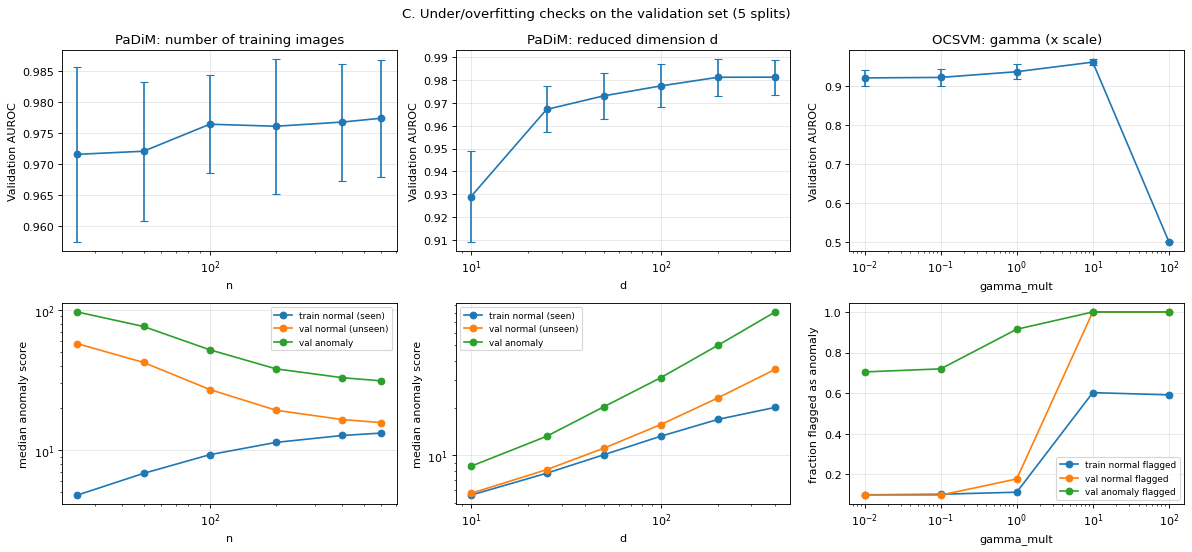

In [26]:
# C-2 ~ C-4 그래프
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for col, (dfx, key, title, logx) in enumerate([(dfC2, 'n', 'PaDiM: number of training images', True),
                                               (dfC3, 'd', 'PaDiM: reduced dimension d', True),
                                               (dfC4, 'gamma_mult', 'OCSVM: gamma (x scale)', True)]):
    s = dfx.groupby(key)['val_AUROC']
    axes[0, col].errorbar(s.mean().index, s.mean().values, yerr=s.std().values, marker='o', capsize=4)
    axes[0, col].set_title(title); axes[0, col].set_ylabel('Validation AUROC')
    if key == 'gamma_mult':
        mm = dfx.groupby(key)[['train_normal_reject', 'val_normal_reject', 'val_anomaly_detect']].mean()
        for c, lab in zip(mm.columns, ['train normal flagged', 'val normal flagged', 'val anomaly flagged']):
            axes[1, col].plot(mm.index, mm[c], marker='o', label=lab)
        axes[1, col].set_ylabel('fraction flagged as anomaly')
    else:
        mm = dfx.groupby(key)[['train_normal', 'val_normal', 'val_anomaly']].mean()
        for c, lab in zip(mm.columns, ['train normal (seen)', 'val normal (unseen)', 'val anomaly']):
            axes[1, col].plot(mm.index, mm[c], marker='o', label=lab)
        axes[1, col].set_yscale('log'); axes[1, col].set_ylabel('median anomaly score')
    axes[1, col].legend(fontsize=8)
    for r in range(2):
        axes[r, col].grid(alpha=0.3)
        if logx:
            axes[r, col].set_xscale('log')
        axes[r, col].set_xlabel(key)
plt.suptitle('C. Under/overfitting checks on the validation set (5 splits)')
plt.tight_layout(); plt.show()

| C-2 학습 이미지 수 | 검증 AUROC | 학습한 정상 점수 | 처음 보는 정상 점수 | 배수 |
|---:|---:|---:|---:|---:|
| 25 | 0.972 | 4.8 | 57.5 | 12.0 |
| 100 | 0.976 | 9.3 | 27.1 | 2.9 |
| 603 | 0.977 | 13.2 | 15.7 | 1.19 |

| C-3 차원 d | 검증 AUROC | 학습한 정상 점수 | 처음 보는 정상 점수 | 배수 |
|---:|---:|---:|---:|---:|
| 10 | 0.929 | 5.6 | 5.7 | 1.03 |
| 100 (기본) | 0.977 | 13.2 | 15.7 | 1.19 |
| 400 | 0.981 | 20.2 | 35.2 | 1.75 |

| C-4 OCSVM gamma | 검증 AUROC | 학습한 정상을 불량 판정 | 처음 보는 정상을 불량 판정 |
|---|---:|---:|---:|
| x0.01 | 0.922 | 10.0% | 9.9% |
| x1 (기본) | 0.938 | 11.3% | 17.8% |
| x10 | 0.963 | 60.3% | 100% |
| x100 | 0.500 | 59.2% | 100% |

그래프 아래 줄을 보면 C-2는 학습 이미지가 적을수록, C-3은 d가 클수록 파란 선(학습한 정상)이랑 주황 선(처음 보는 정상) 사이가 벌어진다. C-4는 gamma x1을 넘어가면서 주황 선이 1.0까지 올라간다.

C-2: 25장으로 학습하면 학습한 정상은 4.8점인데 처음 보는 정상은 57.5점이다. 784개 위치마다 100차원 공분산을 25장으로 추정하면 공분산이 거의 특이 행렬이 돼서, 학습 이미지 점수는 데이터랑 상관없이 (n-1)/√n 근처로 정해진다(25장이면 4.80, 실제 4.78. 50장이면 6.93, 실제 6.83). 학습 이미지에만 맞춰진 과적합이다. 그런데 위 줄 그래프처럼 검증 AUROC는 0.972로 603장일 때(0.977)랑 거의 같다. 불량 점수도 같이 커져서 순서는 유지되기 때문이다. AUROC만 봤으면 과적합인지 몰랐을 거다. 이 상태에서 학습 데이터로 임계값을 정하면 정상도 거의 다 불량으로 나온다.

C-3: d=10이면 두 점수 차이는 거의 없는데 AUROC가 0.929로 낮다. 정보를 너무 많이 버린 과소적합 쪽이다. d를 키우면 AUROC는 200쯤에서 멈추고 점수 차이는 계속 벌어진다(1.19배 → 1.75배). 기본값 100이 그 중간쯤이다. B는 설정을 미리 고정하기로 해서 d는 안 바꿨다.

C-4: gamma를 키우면 OCSVM 경계가 학습 이미지 하나하나를 감싼다. x10에서 검증 AUROC는 0.963으로 제일 높은데, 기본 판정으로는 처음 보는 정상을 100% 불량으로 판정한다. x100은 처음 보는 이미지 점수가 다 같아져서 AUROC가 0.5가 됐다. x10은 OCSVM 기본 경계(0)로 판정하면 쓸 수 없고, B처럼 임계값을 검증 정상 점수로 다시 잡아야 쓸 수 있다.

### D. 0.9668 → 0.9788은 뭐 때문에 올랐나

위 두 PaDiM은 레이어랑 좌우 반전이 동시에 달랐다. B랑 같은 분할 5개에서 하나씩만 바꿔서 테스트 AUROC를 비교했다. D 결과로 설정을 고르지는 않았다.

In [27]:
# D. 레이어(2+3 / 1+2+3) x 좌우 반전(X / O)
CONFIGS = [('layer2+3', ['layer2', 'layer3'], False), ('layer2+3 + flip', ['layer2', 'layer3'], True),
           ('layer1+2+3', ['layer1', 'layer2', 'layer3'], False), ('layer1+2+3 + flip', ['layer1', 'layer2', 'layer3'], True)]
rows, scoresD = [], {}
for seed in SEEDS:
    sp = make_split(seed)
    te = np.r_[sp['test_n'], sp['test_a']]
    yt = np.r_[np.zeros(len(sp['test_n'])), np.ones(len(sp['test_a']))]
    flip = np.random.RandomState(seed).rand(len(sp['train'])) < 0.5
    fmaps, _ = extract(sp['train'], flip=flip)
    S = {}
    for name, layers, use_flip in CONFIGS:
        m = padim_fit(fmaps, np.arange(len(sp['train'])), layers, 100, seed) if use_flip else padim_fit(MAPS, sp['train'], layers, 100, seed)
        S[name] = padim_score(m, MAPS, te)
        rows.append(dict(seed=seed, config=name, AUROC=fast_auc(yt, S[name])))
        del m
    scoresD[seed] = (yt, S)
    del fmaps; torch.cuda.empty_cache()
dfD = pd.DataFrame(rows).pivot(index='seed', columns='config', values='AUROC')[[c[0] for c in CONFIGS]]
print(dfD.round(4).to_string())
print('\n평균 ± 표준편차')
print((dfD.mean().round(4).astype(str) + ' ± ' + dfD.std().round(4).astype(str)).to_string())
print('\n[하나만 바꿨을 때의 차이와 95% 신뢰구간]')
for a, b, what in [('layer1+2+3', 'layer2+3', 'layer1 추가 (반전 X)'), ('layer2+3 + flip', 'layer2+3', '좌우 반전 추가 (layer2+3)'),
                   ('layer1+2+3', 'layer2+3 + flip', '위 실습의 두 설정 (실시간 - 비교 실험)')]:
    txt = []; cnt = 0
    for seed in SEEDS:
        yt, S = scoresD[seed]
        d, (lo, hi) = paired_diff_ci(yt, S[a], S[b])
        cnt += int(lo > 0 or hi < 0)
        txt.append(f'{d:+.4f} [{lo:+.4f}, {hi:+.4f}]')
    print(f'{what}: ' + ' | '.join(txt) + f'  -> CI가 0을 안 포함한 분할 {cnt}/{len(SEEDS)}')

config  layer2+3  layer2+3 + flip  layer1+2+3  layer1+2+3 + flip
seed                                                            
0         0.9726           0.9512      0.9751             0.9604
1         0.9769           0.9608      0.9831             0.9701
2         0.9696           0.9499      0.9711             0.9569
3         0.9758           0.9542      0.9728             0.9526
4         0.9723           0.9549      0.9764             0.9642

평균 ± 표준편차
config
layer2+3              0.9734 ± 0.003
layer2+3 + flip      0.9542 ± 0.0042
layer1+2+3           0.9757 ± 0.0046
layer1+2+3 + flip    0.9608 ± 0.0067

[하나만 바꿨을 때의 차이와 95% 신뢰구간]
layer1 추가 (반전 X): +0.0026 [-0.0046, +0.0104] | +0.0061 [-0.0007, +0.0146] | +0.0016 [-0.0048, +0.0077] | -0.0030 [-0.0126, +0.0056] | +0.0041 [-0.0054, +0.0139]  -> CI가 0을 안 포함한 분할 0/5
좌우 반전 추가 (layer2+3): -0.0213 [-0.0332, -0.0109] | -0.0162 [-0.0270, -0.0070] | -0.0197 [-0.0314, -0.0095] | -0.0216 [-0.0345, -0.0111] | -0.0174 [-0.0297, -0.0074]  ->

| 설정 | 테스트 AUROC |
|---|---:|
| layer2+3 | 0.9734 ± 0.0030 |
| layer2+3 + 좌우 반전 | 0.9542 ± 0.0042 |
| layer1+2+3 | 0.9757 ± 0.0046 |
| layer1+2+3 + 좌우 반전 | 0.9608 ± 0.0067 |

| 하나만 바꿨을 때 | 차이 | 신뢰구간이 0을 안 걸친 분할 |
|---|---|---:|
| layer1 추가 (반전 X) | -0.003 ~ +0.006 | 0 / 5 |
| 좌우 반전 추가 (layer2+3) | -0.022 ~ -0.016 | 5 / 5 |
| 위 두 설정 (실시간 - 비교 실험) | +0.019 ~ +0.024 | 5 / 5 |

실시간 PaDiM이 더 좋았던 건 layer1을 넣어서가 아니라 좌우 반전을 빼서였다. layer1 효과는 5번 다 0 근처라 있다고 보기 어렵다.

데이터 볼 때 PCB를 뒤집으면 이상한 이미지가 될 것 같다고 적었는데 실제로 그랬다. 이 보드는 USB 커넥터가 왼쪽에 있어서, 뒤집은 이미지로 학습하면 커넥터가 오른쪽에 있는 보드도 정상으로 배운다. 그만큼 위치별 정상 범위가 넓어져서 작은 결함이 덜 튀는 것 같다.

In [28]:
# 요약 (아래 정리에 쓴 숫자)
print('A. 원래 분할, seed만 변경:', {c: f'{dfA[c].mean():.4f} ± {dfA[c].std():.4f} (범위 {dfA[c].min():.4f} ~ {dfA[c].max():.4f})' for c in dfA.columns})
print('B. 테스트 AUROC (분할 5개):', {m: f"{dfB[dfB.method == m].AUROC.mean():.3f} ± {dfB[dfB.method == m].AUROC.std():.3f}" for m in METHODS})
print('B. F1 (검증 임계값 / 테스트 최적):', {m: f"{dfB[dfB.method == m].F1_val_thr.mean():.3f} / {dfB[dfB.method == m].F1_test_best.mean():.3f}" for m in METHODS})
print('C-1. AE best epoch 평균:', dfC1.groupby('method').best_epoch.mean().to_dict())
print('D. 설정별 평균:', dfD.mean().round(4).to_dict())
print(f'GPU 최대 메모리 {torch.cuda.max_memory_allocated() / 1e9:.1f}GB')

A. 원래 분할, seed만 변경: {'비교 실험 PaDiM (layer2+3, 반전 O)': '0.9561 ± 0.0043 (범위 0.9500 ~ 0.9619)', '실시간 PaDiM (layer1+2+3, 반전 X)': '0.9783 ± 0.0034 (범위 0.9739 ~ 0.9820)'}
B. 테스트 AUROC (분할 5개): {'PaDiM': '0.973 ± 0.003', 'OCSVM': '0.902 ± 0.024', 'AE(original)': '0.745 ± 0.022', 'AE(fixed)': '0.963 ± 0.011'}
B. F1 (검증 임계값 / 테스트 최적): {'PaDiM': '0.824 / 0.866', 'OCSVM': '0.637 / 0.704', 'AE(original)': '0.016 / 0.545', 'AE(fixed)': '0.794 / 0.846'}
C-1. AE best epoch 평균: {'AE(fixed)': 48.0, 'AE(original)': 48.2}
D. 설정별 평균: {'layer2+3': 0.9734, 'layer2+3 + flip': 0.9542, 'layer1+2+3': 0.9757, 'layer1+2+3 + flip': 0.9608}
GPU 최대 메모리 8.2GB



### E. 원래 분할에서만 결과가 이상했던 이유

B를 돌려보니 AE(original)이 랜덤 분할에서는 0.7대인데 원래 분할에서는 0.266이었다. 차이가 너무 커서 두 가지를 더 봤다.

- E-1: 원래 분할은 CSV 순서대로 앞 80%를 학습, 뒤 20%를 테스트로 쓴다. 혹시 CSV 뒤쪽 정상 이미지가 촬영 조건이 다르면 테스트 정상이 "처음 보는 정상"이 돼버린다. 그래서 앞 80%와 뒤 20%를 구분하는 분류기를 만들어 봤다(잘 구분되면 두 묶음이 다르다는 것). 비교용으로 랜덤 80/20도 같이 해봤고, 원래 분할에서 AE를 다시 학습해서 0.266이 또 나오는지도 봤다.
- E-2: 이 섹션에서는 GPU 메모리 때문에 특징을 float16으로 저장해서 썼다. 이것 때문에 PaDiM 값이 달라졌는지 A랑 같은 seed로 float32로 다시 계산해 봤다.

CSV 앞 80% vs 뒤 20% 구분 AUROC: 0.944
랜덤 80% vs 20% 구분 AUROC (5번): 0.510 ± 0.025
평균 밝기: 앞 80% 55.6, 뒤 20% 46.0



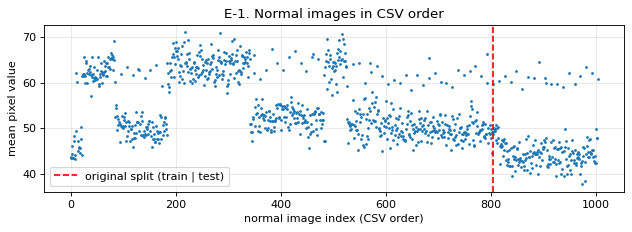

원래 분할 AE(original): 테스트 AUROC 0.2706 (정상 평균 1.9568, 불량 평균 1.8992)
원래 분할 AE(fixed): 테스트 AUROC 0.9367 (정상 평균 0.0021, 불량 평균 0.0039)



In [29]:
# E-1. CSV 앞 80% / 뒤 20% 정상 이미지가 구분되는지 + 원래 분할에서 AE 다시 학습
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
nor_all = np.where(labels == 0)[0]
Xn_feat = StandardScaler().fit_transform(GPOOL[nor_all][:, OC_COLS])


def separability(y_grp, seed=0):
    """5-fold로 두 묶음 구분 AUROC (0.5면 구분 안 됨)"""
    p = cross_val_predict(LogisticRegression(C=0.1, max_iter=5000), Xn_feat, y_grp,
                          cv=StratifiedKFold(5, shuffle=True, random_state=seed), method='decision_function')
    return fast_auc(y_grp, p)


y_seq = (np.arange(len(nor_all)) >= int(len(nor_all) * 0.8)).astype(int)  # 원래 분할의 테스트 쪽(CSV 뒤 20%) = 1
sep_seq = separability(y_seq)
sep_rand = [separability(np.random.RandomState(s).permutation(y_seq), s) for s in range(5)]
print(f'CSV 앞 80% vs 뒤 20% 구분 AUROC: {sep_seq:.3f}')
print(f'랜덤 80% vs 20% 구분 AUROC (5번): {np.mean(sep_rand):.3f} ± {np.std(sep_rand):.3f}')

bright = X_all[_rows(nor_all)].float().mean((1, 2, 3)).cpu().numpy()
print(f'평균 밝기: 앞 80% {bright[y_seq == 0].mean():.1f}, 뒤 20% {bright[y_seq == 1].mean():.1f}')
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(np.arange(len(nor_all)), bright, '.', ms=3)
ax.axvline(int(len(nor_all) * 0.8), color='r', ls='--', label='original split (train | test)')
ax.set_xlabel('normal image index (CSV order)'); ax.set_ylabel('mean pixel value'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('E-1. Normal images in CSV order'); plt.tight_layout(); plt.show()


def ae_train_plain(train_rows, normalize, seed, epochs=AE_EPOCHS, bs=16):
    """위 실습처럼 50 epoch 돌리고 마지막 가중치 사용"""
    torch.manual_seed(seed)
    model = ConvAE().to(device); opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        model.train()
        perm = train_rows[torch.randperm(len(train_rows), generator=g).numpy()]
        for i in range(0, len(perm), bs):
            x = ae_input(perm[i:i + bs], normalize)
            loss = F.mse_loss(model(x), x)
            opt.zero_grad(); loss.backward(); opt.step()
    return model


for name, norm in [('AE(original)', True), ('AE(fixed)', False)]:
    m = ae_train_plain(osp['train'], norm, 0)
    s = np.r_[ae_scores(m, osp['test_n'], norm), ae_scores(m, osp['test_a'], norm)]
    print(f'원래 분할 {name}: 테스트 AUROC {fast_auc(y_te, s):.4f} (정상 평균 {s[y_te == 0].mean():.4f}, 불량 평균 {s[y_te == 1].mean():.4f})')
    del m; torch.cuda.empty_cache()

그래프를 보면 정상 이미지가 CSV 순서대로 밝기가 다른 덩어리 몇 개로 나뉘어 있다. 촬영 세션이 다른 것 같다. 빨간 점선(원래 분할 경계) 오른쪽은 대부분 40 ~ 48 정도로 앞쪽보다 어둡다.

In [30]:
# E-2. float16으로 저장해서 PaDiM 값이 달라졌는지 (A랑 같은 seed, float32로)
@torch.no_grad()
def project_fp32(idx, layers, P, flip=None, bs=32):
    out = []
    for i in range(0, len(idx), bs):
        x = X_all[_rows(idx[i:i + bs])].float() / 255.
        if flip is not None:
            f = torch.as_tensor(flip[i:i + bs], device=device)
            x[f] = x[f].flip(-1)
        backbone((x - MEAN) / STD)
        feat = torch.cat([F.adaptive_avg_pool2d(_feats[l], (28, 28)) for l in layers], 1)  # float32 그대로
        out.append(feat.flatten(2).transpose(1, 2) @ P)
    return torch.cat(out)


rows = []
for seed in SEEDS:
    flip = np.random.RandomState(seed).rand(len(osp['train'])) < 0.5  # A랑 같은 반전
    for name, layers, fl in [('layer2+3, flip', ['layer2', 'layer3'], flip), ('layer1+2+3, no flip', ['layer1', 'layer2', 'layer3'], None)]:
        g = torch.Generator(device=device).manual_seed(seed)  # A랑 같은 투영 행렬
        P = F.normalize(torch.randn(sum(LAYER_CH[l] for l in layers), 100, generator=g, device=device), dim=0)
        Z = project_fp32(osp['train'], layers, P, fl); mu = Z.mean(0); Zc = Z - mu
        cov = torch.einsum('npd,npe->pde', Zc, Zc) / (len(Z) - 1) + 1e-4 * torch.eye(100, device=device)
        inv = torch.linalg.inv(cov.double().cpu()).float().to(device)
        zt = project_fp32(te_rows, layers, P) - mu
        s = torch.einsum('npd,pde,npe->np', zt, inv, zt).clamp_min(0).sqrt().max(1).values.cpu().numpy()
        rows.append(dict(seed=seed, config=name, AUROC=fast_auc(y_te, s)))
        del Z, Zc, zt; torch.cuda.empty_cache()
dfE2 = pd.DataFrame(rows).pivot(index='seed', columns='config', values='AUROC')[['layer2+3, flip', 'layer1+2+3, no flip']]
cmpE2 = pd.DataFrame({'layer2+3, flip (float16, A)': dfA.iloc[:, 0], 'layer2+3, flip (float32)': dfE2.iloc[:, 0],
                      'layer1+2+3 (float16, A)': dfA.iloc[:, 1], 'layer1+2+3 (float32)': dfE2.iloc[:, 1]})
print(cmpE2.round(4).to_string())
print('\n평균 / 표준편차')
print(cmpE2.agg(['mean', 'std']).round(4).to_string())

      layer2+3, flip (float16, A)  layer2+3, flip (float32)  layer1+2+3 (float16, A)  layer1+2+3 (float32)
seed                                                                                                      
0                          0.9500                    0.9500                   0.9765                0.9765
1                          0.9619                    0.9619                   0.9820                0.9820
2                          0.9564                    0.9564                   0.9813                0.9813
3                          0.9546                    0.9546                   0.9739                0.9739
4                          0.9574                    0.9574                   0.9777                0.9777

평균 / 표준편차
      layer2+3, flip (float16, A)  layer2+3, flip (float32)  layer1+2+3 (float16, A)  layer1+2+3 (float32)
mean                       0.9561                    0.9561                   0.9783                0.9783
std                       

E-1: CSV 앞 80%와 뒤 20% 정상 이미지는 분류기로 AUROC 0.944만큼 구분됐다. 랜덤으로 나누면 0.510 ± 0.025로 구분이 안 된다. 평균 밝기도 앞 80%가 55.6, 뒤 20%가 46.0이었다. 원래 분할의 테스트 정상 이미지는 학습 이미지랑 촬영 조건이 다른 이미지였던 거다.

원래 분할에서 AE(original)를 다시 학습하니 0.2706이 나와서 위의 0.266이 거의 그대로 재현됐다. 같은 분할에서 AE(fixed)는 0.9367이었다.

결국 0.266은 두 가지가 겹친 결과였다. 입력 범위가 안 맞아서 복원 오차가 결함보다 밝기에 더 반응했고, 하필 테스트 정상 이미지가 더 어두웠다. 그래서 어두운 정상 이미지가 불량보다 높은 점수를 받았다. 입력 범위만 고쳐도 같은 분할에서 0.94, 분할만 랜덤으로 바꿔도 0.745까지 올라갔다.

PaDiM은 원래 분할(0.956)이랑 랜덤 분할(D의 layer2+3 + 반전, 0.954)이 거의 같았다. 학습 장수(804 vs 603)랑 테스트 불량 수(100 vs 60)가 달라서 조건이 완전히 같은 비교는 아니지만, 이 정도 밝기 차이에는 별로 안 흔들린 것 같다.

E-2: float16이랑 float32 결과가 seed 5개 다 소수 넷째 자리까지 같았다. A ~ D 결과는 저장 방식 때문에 바뀐 게 아니다.

### 추가 분석 정리

| 확인한 것 | 결과 |
|---|---|
| 어떤 방법이 제일 좋나 | PaDiM 0.973 ≈ AE(fixed) 0.963 > OCSVM 0.902 ≫ AE(original) 0.745. PaDiM이랑 AE(fixed) 차이는 확실하지 않음 |
| 0.9668 → 0.9788 이유 | 좌우 반전을 뺀 효과(약 +0.02). layer1 효과는 확인 안 됨 |
| AE 0.266 이유 | 입력 범위 문제 + CSV 순서 분할 때문에 테스트 정상 이미지가 더 어두웠음 |
| 과소적합 / 과적합 | AE(original)은 과소적합. PaDiM은 학습 이미지가 적거나 d가 크면, OCSVM은 gamma가 크면 처음 보는 정상 점수가 커짐(AUROC는 거의 그대로) |
| 위 숫자를 그대로 믿어도 되나 | seed만 바꿔도 0.01씩 움직이고 Best F1은 0.04 ~ 0.07 부풀려져 있음(AE(original) 제외) |

원래 분할 숫자만 봤으면 AE는 이 데이터에 안 맞는다고 결론 냈을 텐데 실제로는 분할이랑 전처리 문제였다.

## 회고

### 실습 내용

VisA pcb4로 정상 이미지만 학습해서 불량을 찾는 이상탐지를 했습니다. PaDiM, AutoEncoder, One-Class SVM을 같은 테스트셋에서 비교했고, PaDiM 모델을 저장해서 Gradio로 이미지를 올리면 바로 판정하는 화면도 만들어 봤습니다.

| 방법 | AUROC (강의 코드 그대로) | AUROC (추가 분석, 랜덤 분할 5개, 좌우 반전 없음) |
|---|---:|---:|
| PaDiM | 0.9668 | 0.973 ± 0.003 |
| AutoEncoder | 0.2660 | 0.745 ± 0.022 (입력 범위 고치면 0.963 ± 0.011) |
| One-Class SVM | 0.8182 | 0.902 ± 0.024 |

### 어려웠던 점

Colab에서 그대로 돌아갈지 걱정했는데 wget 설치 주석만 풀었더니 끝까지 에러 없이 돌아갔습니다. Colab 설정이나 결과 정리할 때는 AI 도구 도움을 받았습니다.

어려웠던 건 결과가 이상하게 나온 부분이었습니다. AE AUROC가 0.266으로 랜덤보다 낮게 나왔는데 에러가 없으니 처음엔 어디가 문제인지 몰랐습니다. 점수 분포 그래프에서 정상 점수가 오히려 높은 걸 보고 입력 값 범위를 찍어 봤더니 입력(-2.10 ~ 2.64)과 Sigmoid 출력(0 ~ 1) 범위가 안 맞았습니다. 추가 분석에서는 여기에 더해 CSV 순서대로 나눈 분할 때문에 테스트 정상 이미지가 더 어두웠다는 것까지 찾았습니다.

추가 분석을 돌릴 때 784개 공분산 행렬의 역행렬을 GPU에서 한 번에 구하다가 `CUDA error: an illegal memory access`가 나서 그 부분만 CPU로 계산했습니다. 중간에 Colab 연결이 끊겨서 출력이 날아간 셀은 다시 돌렸습니다.

### 결과 보고 든 생각

- PaDiM은 점수가 정상/불량으로 잘 갈렸고 히트맵으로 위치도 보여줘서 현장에서 쓰기 좋겠다고 생각했습니다. 다만 210번은 결함 두 곳 중 위쪽만 강하게 나와서 히트맵만 믿기는 아직 이릅니다.
- AE는 "이상한 건 복원이 잘 안 된다"는 원리로 배웠는데, 입력이랑 출력 범위가 안 맞으면 그 원리 자체가 작동을 안 했습니다. 고치니까 같은 분할에서도 0.27이 0.94가 됐습니다.
- 원래 분할에서 테스트 정상 이미지가 더 어두웠던 건, 공장에서 시간이 지나면서 조명이 바뀌는 상황이랑 비슷하다고 생각했습니다. 이 변화에 PaDiM은 거의 안 흔들렸고 원본 AE는 크게 흔들렸습니다.
- AUROC가 0.97이 넘어도 판정 기준을 15로 두면 정상 201장 중 135장이 불량으로 나왔습니다. 학습 이미지를 25장으로 줄인 PaDiM도 AUROC는 0.972였는데 처음 보는 정상 점수가 12배 컸습니다.

### KPT

**Keep**
- 결과 숫자만 보지 않고 점수 분포랑 히트맵을 같이 본 것. AE가 거꾸로 동작하는 것도 분포 그래프에서 처음 알았습니다.
- 결과가 이상하면 넘어가지 않고 입력 범위나 점수 평균을 직접 찍어 본 것.
- 비교할 때 하나씩만 바꾸고 seed 5개랑 신뢰구간으로 우연인지 확인한 것. 덕분에 0.9668 → 0.9788이 좌우 반전 때문이었다는 걸 알았습니다.

**Problem**
- 처음에 seed를 고정하지 않아서 0.9668이 왜 다시 안 나오는지 끝까지 못 밝혔습니다.
- 테스트 불량이 60장이라 분할 하나의 신뢰구간이 ±0.02 ~ 0.04로 넓어서, PaDiM이랑 AE(fixed)처럼 차이가 작은 건 결론을 못 냈습니다.
- C-3, C-4에서 d=200이나 gamma x10이 검증셋에서 더 좋았는데, 하이퍼파라미터를 미리 고정하기로 해서 테스트 비교에는 못 넣었습니다. 튜닝 단계를 처음부터 계획했어야 했습니다.
- AE는 50 epoch에서도 val loss가 계속 내려가고 있어서 충분히 학습된 건지 모르겠습니다.

**Try**
- 검증셋으로 PaDiM d, OCSVM gamma를 먼저 고르고 테스트는 한 번만 돌리는 순서로 다시 해보기
- AE를 100 epoch 이상 돌려서 val loss가 다시 올라가는 지점 찾기
- CSV 뒤쪽 어두운 정상 이미지를 일부러 테스트에만 넣어서 조명 변화에 강한 방법 비교하기
- 행렬 연산으로 바꾼 PaDiM으로 한 장 추론 시간을 재서 지금(약 0.2초)이랑 비교하기

같은 AE 코드인데 분할 방법 하나로 AUROC가 0.27이 되기도 하고 0.75가 되기도 해서, 데이터를 어떻게 나누는지가 모델보다 결과를 더 크게 바꿨습니다.